# RQ2 Monotonicity Training Sweep

This notebook performs the main RQ2 experiments for monotonicity-regularized training.

## Goal
Train next-day maximum temperature predictors with the objective

$$
L = L_{\text{task}} + \lambda_{\text{mono}} L_{\text{mono}},
$$

where:

- $L_{\text{task}}$ is the standard regression loss (MSE),
- $L_{\text{mono}}$ is a pairwise hinge-style monotonicity penalty,
- $\lambda_{\text{mono}}$ controls the strength of the monotonicity prior.

## Inputs from notebook 07
This notebook uses the monotonicity audit outputs from notebook 07:

- the selected constrained features,
- the selected monotonic direction for each feature,
- and the saved local pair-index arrays for train/val/test.

## Main questions
1. Can monotonicity regularization reduce monotonicity violations?
2. What is the effect on RMSE and MAE?
3. Which $\lambda_{\text{mono}}$ gives the best trade-off?

In [1]:
# Cell 1 - Imports and notebook setup
from __future__ import annotations
from pathlib import Path
import copy
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from IPython.display import display

from src.models import MLPRegressor
from src.training import DEFAULT_TRAIN_CONFIG, TrainConfig, eval_loader_reg, make_standard_experiment_data
from src.monotonicity import (
    combined_monotonicity_loss,
    compute_gradient_sign_audit,
    load_chosen_pair_artifacts,
    load_training_spec,
    make_counterfactual_sweep_df,
    make_pair_index_dict_from_manifest,
    make_sign_dict,
    pairwise_metrics_from_predictions,
    predict_numpy,
    select_representative_rows,
)

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

PROJECT_ROOT = Path("..").resolve()
RESULTS_ROOT = PROJECT_ROOT / "results"
MONO_AUDIT_DIR = RESULTS_ROOT / "monotonicity_audit"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Project root:", PROJECT_ROOT)
print("Results root:", RESULTS_ROOT)
print("Monotonicity audit dir:", MONO_AUDIT_DIR)
print("Using device:", device)

Project root: <project root>
Results root: <project root>/results
Monotonicity audit dir: <project root>/results/monotonicity_audit
Using device: cuda


In [2]:
# Cell 2 - Helper cell: safe scalar coercion for pandas / numpy values
#from __future__ import annotations

import math
from typing import Any, cast

#import numpy as np
import pandas as pd


def to_py_float(value: Any, *, name: str) -> float:
    """
    Convert a pandas/numpy scalar to a validated Python float.
    """
    series = pd.to_numeric(pd.Series([value]), errors="raise")
    arr = series.to_numpy(dtype=np.float64)
    scalar = np.asarray(arr).reshape(()).item()
    out = float(cast(float, scalar))

    if not math.isfinite(out):
        raise ValueError(f"{name} must be finite, got {out!r}")

    return out


def to_py_int(value: Any, *, name: str) -> int:
    """
    Convert a pandas/numpy scalar to a validated Python int.
    """
    out = to_py_float(value, name=name)

    if not out.is_integer():
        raise ValueError(f"{name} must be integer-valued, got {out!r}")

    return int(out)

In [3]:
# Cell 3 - Load data, training spec, and chosen pair artifacts

config = TrainConfig(
    lr=DEFAULT_TRAIN_CONFIG.lr,
    batch_size=DEFAULT_TRAIN_CONFIG.batch_size,
    eval_batch_size=DEFAULT_TRAIN_CONFIG.eval_batch_size,
    num_epochs=80,
    weight_decay=DEFAULT_TRAIN_CONFIG.weight_decay,
    early_stopping_patience=10,
    early_stopping_min_delta=0.0,
)

data = make_standard_experiment_data(PROJECT_ROOT, config)

train_loader = data.train_loader
val_loader   = data.val_loader
test_loader  = data.test_loader

feature_cols = data.feature_cols

manifest_df, pair_idx_store = load_chosen_pair_artifacts(MONO_AUDIT_DIR)
training_spec_df = load_training_spec(MONO_AUDIT_DIR, name="training_spec_main")
training_spec_with_optional_df = load_training_spec(MONO_AUDIT_DIR, name="training_spec_with_optional")

constrained_features = training_spec_df["feature"].astype(str).tolist()
sign_dict = make_sign_dict(training_spec_df)

train_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="train",
    features=constrained_features,
)
val_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="val",
    features=constrained_features,
)
test_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="test",
    features=constrained_features,
)

print("Train/val/test sizes:", len(data.train_df), len(data.val_df), len(data.test_df))
print("Feature columns:", feature_cols)
print("Constrained features:", constrained_features)
print("Sign dict:", sign_dict)

print("\nMain training spec:")
display(training_spec_df.round(4))

print("\nOptional training spec (for later ablations if needed):")
display(training_spec_with_optional_df.round(4))

Train/val/test sizes: 2556 547 549
Feature columns: ['tmin', 'tavg', 'tmax', 'prcp', 'dayofyear_sin', 'dayofyear_cos', 'rand_noise']
Constrained features: ['tavg', 'tmax']
Sign dict: {'tavg': 1, 'tmax': 1}

Main training spec:


,feature,direction,sign,chosen_setting,chosen_train_n_pairs,train_label_violation_rate,test_label_violation_rate,test_baseline_violation_rate,test_grad_violation_rate,confidence,rationale,notes
0,tavg,nondecreasing,1,local_knn_strict,340.0,0.1353,0.1298,0.0000,0.0000,high,Warmer recent average temperature should usual...,baseline is already more monotone than labels ...
1,tmax,nondecreasing,1,local_knn_medium,5113.0,0.2501,0.2335,0.0078,0.0018,medium,Warmer recent maximum temperature should usual...,baseline is already more monotone than labels ...



Optional training spec (for later ablations if needed):


,feature,direction,sign,chosen_setting,chosen_train_n_pairs,train_label_violation_rate,test_label_violation_rate,test_baseline_violation_rate,test_grad_violation_rate,confidence,rationale,notes
0,tavg,nondecreasing,1,local_knn_strict,340.0,0.1353,0.1298,0.0000,0.0000,high,Warmer recent average temperature should usual...,baseline is already more monotone than labels ...
1,tmax,nondecreasing,1,local_knn_medium,5113.0,0.2501,0.2335,0.0078,0.0018,medium,Warmer recent maximum temperature should usual...,baseline is already more monotone than labels ...


,split,feature,n_pairs
0,train,tavg,340
1,train,tmax,5113
2,val,tavg,128
3,val,tmax,1634
4,test,tavg,131
5,test,tmax,1533


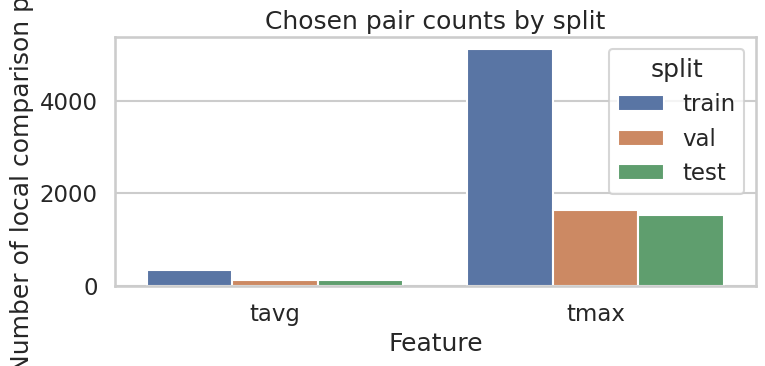

In [4]:
# Cell 4 - Inspect chosen pair counts for the constrained features

pair_count_rows = []
for split_name, pair_dict in [
    ("train", train_pair_index_dict),
    ("val", val_pair_index_dict),
    ("test", test_pair_index_dict),
]:
    for feature in constrained_features:
        pair_count_rows.append(
            {
                "split": split_name,
                "feature": feature,
                "n_pairs": int(len(pair_dict.get(feature, np.empty((0, 2), dtype=np.int64)))),
            }
        )

pair_count_df = pd.DataFrame(pair_count_rows)
display(pair_count_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=pair_count_df, x="feature", y="n_pairs", hue="split")
plt.title("Chosen pair counts by split")
plt.xlabel("Feature")
plt.ylabel("Number of local comparison pairs")
plt.tight_layout()
plt.show()

## Training objective and evaluation

The training objective is:

$$
L = L_{\text{task}} + \lambda_{\text{mono}} L_{\text{mono}}.
$$

### Task loss
The predictive loss is the mean squared error:

$$
L_{\text{task}} = \frac{1}{N}\sum_{i=1}^N \bigl(\hat y_i - y_i\bigr)^2.
$$

### Monotonicity loss
For each constrained feature, local comparison pairs are taken from notebook 07.  
For a pair $(i,k)$, with row $i$ having the larger constrained feature value, the desired monotonicity condition is:

$$
s \bigl(f(\mathbf{x}^{(i)}) - f(\mathbf{x}^{(k)})\bigr) \ge 0,
$$

where $s \in \{+1,-1\}$ indicates whether the feature should be nondecreasing or nonincreasing.

The hinge penalty is:

$$
\max\bigl(0,\,- s (f(\mathbf{x}^{(i)}) - f(\mathbf{x}^{(k)}))\bigr).
$$

### Main evaluation metrics
This notebook reports:

- predictive metrics:
  - MSE
  - RMSE
  - MAE

- pairwise monotonicity metrics:
  - violation rate
  - mean hinge violation

- gradient-sign diagnostics:
  - wrong-sign gradient rate for each constrained feature

In [5]:
# Cell 5 - Experiment settings

lambda_values = [0.0, 0.1, 1.0, 10.0, 100.0]
seeds = [0, 1, 2, 3, 4]

# Monotonicity-loss settings
mono_margin = 0.0
mono_reduction = "mean_over_features"
max_pairs_per_feature_train = 1024   # None to use all train pairs every batch
max_pairs_per_feature_eval = None    # use all pairs for val/test evaluation

# Qualitative comparison settings
selected_seed_for_store = 0

print("lambda_values:", lambda_values)
print("seeds:", seeds)
print("mono_margin:", mono_margin)
print("mono_reduction:", mono_reduction)
print("max_pairs_per_feature_train:", max_pairs_per_feature_train)
print("max_pairs_per_feature_eval:", max_pairs_per_feature_eval)

lambda_values: [0.0, 0.1, 1.0, 10.0, 100.0]
seeds: [0, 1, 2, 3, 4]
mono_margin: 0.0
mono_reduction: mean_over_features
max_pairs_per_feature_train: 1024
max_pairs_per_feature_eval: None


In [6]:
# Cell 6 - Helper functions for training and evaluation

class SimpleEarlyStopper:
    def __init__(self, patience: int, min_delta: float = 0.0) -> None:
        self.patience = patience
        self.min_delta = min_delta
        self.best_value = float("inf")
        self.num_bad_epochs = 0
        self.best_state: dict[str, torch.Tensor] | None = None

    def step(self, value: float, model: nn.Module) -> bool:
        if value + self.min_delta < self.best_value:
            self.best_value = value
            self.num_bad_epochs = 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False

        self.num_bad_epochs += 1
        return self.num_bad_epochs >= self.patience

    def restore_best(self, model: nn.Module) -> None:
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


def should_log(epoch: int, num_epochs: int) -> bool:
    return (epoch + 1) == 1 or (epoch + 1) % 10 == 0 or (epoch + 1) == num_epochs


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def instantiate_model(input_dim: int) -> MLPRegressor:
    return MLPRegressor(
        input_dim=input_dim,
        hidden_dims=(64, 64),
        dropout=0.0,
    )


def prefix_dict(d: dict[str, float], prefix: str) -> dict[str, float]:
    return {f"{prefix}_{k}": float(v) for k, v in d.items()}


def safe_mean(values: list[float]) -> float:
    if len(values) == 0:
        return float("nan")
    return float(np.mean(values))


def evaluate_monotonic_suite(
    model: nn.Module,
    X_np: np.ndarray,
    y_np: np.ndarray,
    *,
    split_name: str,
    pair_index_dict: dict[str, np.ndarray],
    sign_dict: dict[str, int],
    feature_cols: list[str],
    device: str = "cpu",
) -> dict[str, float]:
    """
    Evaluate predictive metrics, pairwise monotonicity metrics, and
    gradient-sign diagnostics on one split.
    """
    preds = predict_numpy(model, X_np, device=device)
    y_true = np.asarray(y_np, dtype=np.float64).ravel()

    mse = float(np.mean((preds - y_true) ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(preds - y_true)))

    out: dict[str, float] = {
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
    }

    pair_viols: list[float] = []
    pair_hinges: list[float] = []
    grad_viols: list[float] = []

    for feature in sign_dict.keys():
        sign = int(sign_dict[feature])
        pair_idx = pair_index_dict.get(feature, np.empty((0, 2), dtype=np.int64))

        pair_metrics = pairwise_metrics_from_predictions(preds, pair_idx, sign)
        out[f"pair_n_pairs_{feature}"] = float(pair_metrics["n_pairs"])
        out[f"pair_violation_{feature}"] = float(pair_metrics["violation_rate"])
        out[f"pair_mean_hinge_{feature}"] = float(pair_metrics["mean_hinge_violation"])

        if not np.isnan(pair_metrics["violation_rate"]):
            pair_viols.append(float(pair_metrics["violation_rate"]))
        if not np.isnan(pair_metrics["mean_hinge_violation"]):
            pair_hinges.append(float(pair_metrics["mean_hinge_violation"]))

        grad_metrics = compute_gradient_sign_audit(
            model,
            X_np,
            split=split_name,
            constrained_feature=feature,
            sign=sign,
            feature_cols=feature_cols,
            device=device,
        )
        out[f"grad_violation_{feature}"] = float(grad_metrics["grad_violation_rate"])
        out[f"grad_mean_signed_{feature}"] = float(grad_metrics["mean_signed_gradient"])

        if not np.isnan(grad_metrics["grad_violation_rate"]):
            grad_viols.append(float(grad_metrics["grad_violation_rate"]))

    out["pair_violation_macro"] = safe_mean(pair_viols)
    out["pair_mean_hinge_macro"] = safe_mean(pair_hinges)
    out["grad_violation_macro"] = safe_mean(grad_viols)

    return out

In [7]:
# Cell 7 - Gradient-debug helper functions

def get_signed_gradients(
    model: nn.Module,
    X_np: np.ndarray,
    *,
    constrained_feature: str,
    sign: int,
    feature_cols: list[str],
    device: str = "cpu",
    batch_size: int = 512,
) -> np.ndarray:
    """
    Return signed gradients:
        sign * d f(x) / d x_j
    for all rows in X_np.
    """
    j = feature_cols.index(constrained_feature)
    X_arr = np.asarray(X_np, dtype=np.float32)

    signed_grads_all = []

    model = model.to(device)
    model.eval()

    for start in range(0, len(X_arr), batch_size):
        xb = torch.tensor(
            X_arr[start : start + batch_size],
            dtype=torch.float32,
            device=device,
            requires_grad=True,
        )
        preds = model(xb)
        grads = torch.autograd.grad(preds.sum(), xb, create_graph=False)[0]
        signed_grads = float(sign) * grads[:, j].detach().cpu().numpy()
        signed_grads_all.append(signed_grads)

    return np.concatenate(signed_grads_all).astype(np.float64)


def finite_difference_slope(
    model: nn.Module,
    x_scaled: np.ndarray,
    *,
    feature_idx: int,
    eps: float = 1e-3,
    device: str = "cpu",
) -> float:
    """
    Approximate d f(x) / d x_j with a centered finite difference.
    """
    x_plus = np.asarray(x_scaled, dtype=np.float32).copy()
    x_minus = np.asarray(x_scaled, dtype=np.float32).copy()

    x_plus[feature_idx] += eps
    x_minus[feature_idx] -= eps

    y_plus = predict_numpy(model, x_plus[None, :], device=device)[0]
    y_minus = predict_numpy(model, x_minus[None, :], device=device)[0]

    return float((y_plus - y_minus) / (2 * eps))

In [8]:
# Cell 8 - Training loop for monotonicity-regularized regression

def train_monotonic_regressor(
    model: nn.Module,
    *,
    train_loader,
    val_loader,
    X_train_np: np.ndarray,
    X_val_np: np.ndarray,
    train_pair_index_dict: dict[str, np.ndarray],
    val_pair_index_dict: dict[str, np.ndarray],
    sign_dict: dict[str, int],
    config: TrainConfig,
    lambda_mono: float,
    device: str = "cpu",
    mono_margin: float = 0.0,
    mono_reduction: str = "mean_over_features",
    max_pairs_per_feature_train: int | None = None,
    max_pairs_per_feature_eval: int | None = None,
    seed: int = 0,
) -> tuple[nn.Module, list[dict[str, float]]]:
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.lr,
        weight_decay=config.weight_decay,
    )
    mse_loss = nn.MSELoss()

    X_train_t = torch.as_tensor(X_train_np, dtype=torch.float32, device=device)
    X_val_t   = torch.as_tensor(X_val_np, dtype=torch.float32, device=device)

    history: list[dict[str, float]] = []

    stopper = None
    if config.early_stopping_patience is not None:
        stopper = SimpleEarlyStopper(
            patience=int(config.early_stopping_patience),
            min_delta=float(config.early_stopping_min_delta),
        )

    rng = np.random.default_rng(seed)

    for epoch in range(config.num_epochs):
        model.train()
        running_task = 0.0
        running_total = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(set_to_none=True)

            task_loss = mse_loss(model(xb), yb)

            if lambda_mono > 0.0 and len(sign_dict) > 0:
                mono_loss_batch, _ = combined_monotonicity_loss(
                    model,
                    X_train_t,
                    train_pair_index_dict,
                    sign_dict,
                    margin=mono_margin,
                    feature_weights=None,
                    max_pairs_per_feature=max_pairs_per_feature_train,
                    rng=rng,
                    reduction=mono_reduction,
                )
            else:
                mono_loss_batch = torch.zeros((), device=device, dtype=task_loss.dtype)

            total_loss = task_loss + lambda_mono * mono_loss_batch
            total_loss.backward()
            optimizer.step()

            bs = xb.size(0)
            running_task += task_loss.item() * bs
            running_total += total_loss.item() * bs
            n_train += bs

        train_task = running_task / max(n_train, 1)

        # Deterministic monotonicity evaluation on full train/val splits
        model.eval()
        with torch.no_grad():
            train_mono_tensor, train_mono_details = combined_monotonicity_loss(
                model,
                X_train_t,
                train_pair_index_dict,
                sign_dict,
                margin=mono_margin,
                feature_weights=None,
                max_pairs_per_feature=max_pairs_per_feature_eval,
                rng=None,
                reduction=mono_reduction,
            )

            val_mono_tensor, val_mono_details = combined_monotonicity_loss(
                model,
                X_val_t,
                val_pair_index_dict,
                sign_dict,
                margin=mono_margin,
                feature_weights=None,
                max_pairs_per_feature=max_pairs_per_feature_eval,
                rng=None,
                reduction=mono_reduction,
            )

        train_mono = float(train_mono_tensor.item())
        val_mono = float(val_mono_tensor.item())

        val_task = float(eval_loader_reg(model, val_loader, device=device)["mse"])

        train_total = float(train_task + lambda_mono * train_mono)
        val_total = float(val_task + lambda_mono * val_mono)

        row: dict[str, float] = {
            "epoch": float(epoch),
            "train_task_loss": float(train_task),
            "train_mono_loss": float(train_mono),
            "train_total_loss": float(train_total),
            "val_task_loss": float(val_task),
            "val_mono_loss": float(val_mono),
            "val_total_loss": float(val_total),
        }

        for feature in sign_dict.keys():
            row[f"train_mono_loss_{feature}"] = float(train_mono_details.get(f"mono_loss_{feature}", np.nan))
            row[f"val_mono_loss_{feature}"] = float(val_mono_details.get(f"mono_loss_{feature}", np.nan))

        history.append(row)

        if should_log(epoch, config.num_epochs):
            print(
                f"Epoch {epoch+1:03d} | "
                f"train_task={train_task:.4f} train_mono={train_mono:.4f} train_total={train_total:.4f} | "
                f"val_task={val_task:.4f} val_mono={val_mono:.4f} val_total={val_total:.4f}"
            )

        if stopper is not None:
            if stopper.step(val_total, model):
                print(
                    f"Early stopping at epoch {epoch+1:03d} | "
                    f"best_val_total={stopper.best_value:.6f}"
                )
                break

    if stopper is not None:
        stopper.restore_best(model)

    return model, history

In [9]:
# Cell 9 - Full lambda sweep across seeds

records: list[dict[str, float]] = []
history_frames: list[pd.DataFrame] = []
selected_model_store: dict[float, nn.Module] = {}

for lam in lambda_values:
    for seed in seeds:
        print(f"\nRunning monotonic training: lambda_mono={lam:g}, seed={seed}")
        set_seed(seed)

        model = instantiate_model(input_dim=len(feature_cols))

        model, history = train_monotonic_regressor(
            model,
            train_loader=train_loader,
            val_loader=val_loader,
            X_train_np=data.X_train,
            X_val_np=data.X_val,
            train_pair_index_dict=train_pair_index_dict,
            val_pair_index_dict=val_pair_index_dict,
            sign_dict=sign_dict,
            config=config,
            lambda_mono=float(lam),
            device=device,
            mono_margin=mono_margin,
            mono_reduction=mono_reduction,
            max_pairs_per_feature_train=max_pairs_per_feature_train,
            max_pairs_per_feature_eval=max_pairs_per_feature_eval,
            seed=seed,
        )

        hist_df = pd.DataFrame(history)
        hist_df["lambda_mono"] = float(lam)
        hist_df["seed"] = float(seed)
        history_frames.append(hist_df)

        best_idx = hist_df["val_total_loss"].astype(float).idxmin()
        best_row = hist_df.loc[best_idx]

        train_eval = evaluate_monotonic_suite(
            model,
            data.X_train,
            data.y_train,
            split_name="train",
            pair_index_dict=train_pair_index_dict,
            sign_dict=sign_dict,
            feature_cols=feature_cols,
            device=device,
        )

        val_eval = evaluate_monotonic_suite(
            model,
            data.X_val,
            data.y_val,
            split_name="val",
            pair_index_dict=val_pair_index_dict,
            sign_dict=sign_dict,
            feature_cols=feature_cols,
            device=device,
        )

        test_eval = evaluate_monotonic_suite(
            model,
            data.X_test,
            data.y_test,
            split_name="test",
            pair_index_dict=test_pair_index_dict,
            sign_dict=sign_dict,
            feature_cols=feature_cols,
            device=device,
        )

        record: dict[str, float] = {
            "lambda_mono": float(lam),
            "seed": float(seed),
            "n_epochs_trained": float(len(hist_df)),
            "best_epoch": to_py_float(best_row["epoch"], name="best_epoch"),
            "best_val_task": to_py_float(best_row["val_task_loss"], name="best_val_task"),
            "best_val_mono": to_py_float(best_row["val_mono_loss"], name="best_val_mono"),
            "best_val_total": to_py_float(best_row["val_total_loss"], name="best_val_total"),
        }
        record.update(prefix_dict(train_eval, "train"))
        record.update(prefix_dict(val_eval, "val"))
        record.update(prefix_dict(test_eval, "test"))

        records.append(record)

        if seed == selected_seed_for_store:
            selected_model_store[float(lam)] = copy.deepcopy(model).to("cpu")

sweep_df = pd.DataFrame(records)
history_df = pd.concat(history_frames, ignore_index=True)

#print("\nRaw sweep results:")
#display(sweep_df.round(4))


Running monotonic training: lambda_mono=0, seed=0
Epoch 001 | train_task=176.7362 train_mono=0.0465 train_total=176.7362 | val_task=155.3286 val_mono=0.0367 val_total=155.3286
Epoch 010 | train_task=6.1922 train_mono=0.0042 train_total=6.1922 | val_task=6.7509 val_mono=0.0018 val_total=6.7509
Epoch 020 | train_task=5.8585 train_mono=0.0006 train_total=5.8585 | val_task=6.2420 val_mono=0.0009 val_total=6.2420
Epoch 030 | train_task=5.6236 train_mono=0.0003 train_total=5.6236 | val_task=6.0566 val_mono=0.0011 val_total=6.0566
Epoch 040 | train_task=5.5313 train_mono=0.0004 train_total=5.5313 | val_task=6.0031 val_mono=0.0012 val_total=6.0031
Early stopping at epoch 048 | best_val_total=5.973720

Running monotonic training: lambda_mono=0, seed=1
Epoch 001 | train_task=173.1674 train_mono=0.0535 train_total=173.1674 | val_task=148.5683 val_mono=0.0420 val_total=148.5683
Epoch 010 | train_task=6.2654 train_mono=0.0011 train_total=6.2654 | val_task=7.0005 val_mono=0.0021 val_total=7.0005
Ep

In [10]:
# Cell 10 - Optional replacement for duplicate full raw sweep display
print("\nRaw sweep results:")
main_run_preview = (
    sweep_df[
        [
            "lambda_mono",
            "seed",
            "best_val_total",
            "test_rmse",
            "test_mae",
            "test_pair_violation_macro",
            "test_grad_violation_macro",
        ]
    ]
    .sort_values(["lambda_mono", "seed"])
    .reset_index(drop=True)
    .round(4)
)

display(main_run_preview)


Raw sweep results:


,lambda_mono,seed,best_val_total,test_rmse,test_mae,test_pair_violation_macro,test_grad_violation_macro
0,0.0,0.0,5.9737,2.3235,1.8316,0.0013,0.0
1,0.0,1.0,5.9558,2.3391,1.8459,0.0023,0.0
2,0.0,2.0,6.0488,2.3173,1.8162,0.0003,0.0
3,0.0,3.0,5.9540,2.3149,1.8123,0.0020,0.0
4,0.0,4.0,5.9999,2.3074,1.8028,0.0016,0.0
5,0.1,0.0,5.9784,2.3211,1.8290,0.0013,0.0
6,0.1,1.0,5.9549,2.3392,1.8454,0.0026,0.0
7,0.1,2.0,6.0323,2.3175,1.8150,0.0003,0.0
8,0.1,3.0,6.0247,2.3117,1.8152,0.0010,0.0
9,0.1,4.0,5.9925,2.3076,1.8023,0.0016,0.0


In [11]:
# Cell 11 - Debug check 1: inspect raw gradient-sign metrics with high precision

grad_cols = ["lambda_mono", "seed"]
for feature in constrained_features:
    grad_cols.append(f"test_grad_violation_{feature}")
    grad_cols.append(f"test_grad_mean_signed_{feature}")

print("Per-run raw gradient diagnostics (high precision):")
with pd.option_context("display.float_format", lambda x: f"{x:.8f}"):
    display(
        sweep_df[grad_cols]
        .sort_values(["lambda_mono", "seed"])
        .reset_index(drop=True)
    )

Per-run raw gradient diagnostics (high precision):


,lambda_mono,seed,test_grad_violation_tavg,test_grad_mean_signed_tavg,test_grad_violation_tmax,test_grad_mean_signed_tmax
0,0.00000000,0.00000000,0.00000000,4.37730671,0.00000000,3.44566838
1,0.00000000,1.00000000,0.00000000,5.90387538,0.00000000,2.50906179
2,0.00000000,2.00000000,0.00000000,4.53295469,0.00000000,3.42837048
3,0.00000000,3.00000000,0.00000000,5.48612389,0.00000000,2.82128451
4,0.00000000,4.00000000,0.00000000,5.46496611,0.00000000,2.87550832
5,0.10000000,0.00000000,0.00000000,4.33947393,0.00000000,3.45381976
6,0.10000000,1.00000000,0.00000000,5.97554874,0.00000000,2.46567261
7,0.10000000,2.00000000,0.00000000,4.54004796,0.00000000,3.42385338
8,0.10000000,3.00000000,0.00000000,4.68199827,0.00000000,3.25967969
9,0.10000000,4.00000000,0.00000000,5.46200042,0.00000000,2.90556555


In [12]:
# Cell 12 - Save raw sweep outputs

results_dir = RESULTS_ROOT / "monotonicity_training" / "sweep_main"
results_dir.mkdir(parents=True, exist_ok=True)

sweep_df.to_csv(results_dir / "runs_raw.csv", index=False)
history_df.to_csv(results_dir / "history_raw.csv", index=False)

config_payload = {
    "lambda_values": [float(v) for v in lambda_values],
    "seeds": [int(s) for s in seeds],
    "mono_margin": float(mono_margin),
    "mono_reduction": mono_reduction,
    "max_pairs_per_feature_train": None if max_pairs_per_feature_train is None else int(max_pairs_per_feature_train),
    "max_pairs_per_feature_eval": None if max_pairs_per_feature_eval is None else int(max_pairs_per_feature_eval),
    "selected_seed_for_store": int(selected_seed_for_store),
    "training_spec_main": training_spec_df.to_dict(orient="records"),
    "feature_cols": list(feature_cols),
    "early_stopping_monitor": "val_total",
    "train_config": {
        "lr": config.lr,
        "batch_size": config.batch_size,
        "eval_batch_size": config.eval_batch_size,
        "num_epochs": config.num_epochs,
        "weight_decay": config.weight_decay,
        "early_stopping_patience": config.early_stopping_patience,
        "early_stopping_min_delta": config.early_stopping_min_delta,
    },
}
with open(results_dir / "config.json", "w") as fh:
    json.dump(config_payload, fh, indent=2)

print("Saved raw sweep outputs to:", results_dir)

Saved raw sweep outputs to: <project root>/results/monotonicity_training/sweep_main


In [13]:
# Cell 13 - Aggregate sweep results across seeds

agg_spec = {
    "best_val_total_mean": ("best_val_total", "mean"),
    "best_val_total_std": ("best_val_total", "std"),
    "best_val_task_mean": ("best_val_task", "mean"),
    "best_val_mono_mean": ("best_val_mono", "mean"),
    "n_epochs_mean": ("n_epochs_trained", "mean"),
    "test_rmse_mean": ("test_rmse", "mean"),
    "test_rmse_std": ("test_rmse", "std"),
    "test_mae_mean": ("test_mae", "mean"),
    "test_pair_violation_macro_mean": ("test_pair_violation_macro", "mean"),
    "test_pair_violation_macro_std": ("test_pair_violation_macro", "std"),
    "test_pair_mean_hinge_macro_mean": ("test_pair_mean_hinge_macro", "mean"),
    "test_grad_violation_macro_mean": ("test_grad_violation_macro", "mean"),
    "test_grad_violation_macro_std": ("test_grad_violation_macro", "std"),
    "val_rmse_mean": ("val_rmse", "mean"),
    "val_pair_violation_macro_mean": ("val_pair_violation_macro", "mean"),
    "val_grad_violation_macro_mean": ("val_grad_violation_macro", "mean"),
}

for feature in constrained_features:
    agg_spec[f"test_pair_violation_{feature}_mean"] = (f"test_pair_violation_{feature}", "mean")
    agg_spec[f"test_pair_violation_{feature}_std"] = (f"test_pair_violation_{feature}", "std")
    agg_spec[f"test_pair_mean_hinge_{feature}_mean"] = (f"test_pair_mean_hinge_{feature}", "mean")
    agg_spec[f"test_grad_violation_{feature}_mean"] = (f"test_grad_violation_{feature}", "mean")
    agg_spec[f"test_grad_violation_{feature}_std"] = (f"test_grad_violation_{feature}", "std")

agg_df = sweep_df.groupby("lambda_mono").agg(**agg_spec).reset_index()
agg_df.to_csv(results_dir / "sweep_summary.csv", index=False)

display(agg_df.round(4))

,lambda_mono,best_val_total_mean,best_val_total_std,best_val_task_mean,best_val_mono_mean,n_epochs_mean,test_rmse_mean,test_rmse_std,test_mae_mean,test_pair_violation_macro_mean,test_pair_violation_macro_std,test_pair_mean_hinge_macro_mean,test_grad_violation_macro_mean,test_grad_violation_macro_std,val_rmse_mean,val_pair_violation_macro_mean,val_grad_violation_macro_mean,test_pair_violation_tavg_mean,test_pair_violation_tavg_std,test_pair_mean_hinge_tavg_mean,test_grad_violation_tavg_mean,test_grad_violation_tavg_std,test_pair_violation_tmax_mean,test_pair_violation_tmax_std,test_pair_mean_hinge_tmax_mean,test_grad_violation_tmax_mean,test_grad_violation_tmax_std
0,0.0,5.9864,0.0395,5.9864,0.0016,58.4,2.3204,0.0119,1.8218,0.0015,0.0008,0.0007,0.0,0.0,2.4467,0.0024,0.0000,0.0,0.0,0.0,0.0,0.0,0.0030,0.0015,0.0013,0.0,0.0
1,0.1,5.9965,0.0322,5.9964,0.0016,55.0,2.3194,0.0122,1.8214,0.0014,0.0008,0.0007,0.0,0.0,2.4487,0.0022,0.0000,0.0,0.0,0.0,0.0,0.0,0.0027,0.0017,0.0015,0.0,0.0
2,1.0,5.9882,0.0348,5.9865,0.0018,59.0,2.3126,0.0051,1.8133,0.0016,0.0010,0.0008,0.0,0.0,2.4467,0.0023,0.0002,0.0,0.0,0.0,0.0,0.0,0.0033,0.0020,0.0015,0.0,0.0
3,10.0,5.9916,0.0231,5.9778,0.0014,55.0,2.3112,0.0095,1.8141,0.0015,0.0005,0.0006,0.0,0.0,2.4449,0.0022,0.0000,0.0,0.0,0.0,0.0,0.0,0.0030,0.0011,0.0013,0.0,0.0
4,100.0,6.0823,0.0734,5.9993,0.0008,50.0,2.3237,0.0072,1.8290,0.0010,0.0003,0.0003,0.0,0.0,2.4493,0.0014,0.0000,0.0,0.0,0.0,0.0,0.0,0.0020,0.0007,0.0007,0.0,0.0


In [14]:
# Cell 14 - Debug check 2: aggregate per-feature gradient diagnostics

grad_summary_cols = ["lambda_mono"]
for feature in constrained_features:
    grad_summary_cols.append(f"test_grad_violation_{feature}_mean")
    grad_summary_cols.append(f"test_grad_violation_{feature}_std")

print("Aggregated per-feature gradient-sign violation rates:")
with pd.option_context("display.float_format", lambda x: f"{x:.8f}"):
    display(agg_df[grad_summary_cols].copy())

Aggregated per-feature gradient-sign violation rates:


,lambda_mono,test_grad_violation_tavg_mean,test_grad_violation_tavg_std,test_grad_violation_tmax_mean,test_grad_violation_tmax_std
0,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000
1,0.10000000,0.00000000,0.00000000,0.00000000,0.00000000
2,1.00000000,0.00000000,0.00000000,0.00000000,0.00000000
3,10.00000000,0.00000000,0.00000000,0.00000000,0.00000000
4,100.00000000,0.00000000,0.00000000,0.00000000,0.00000000


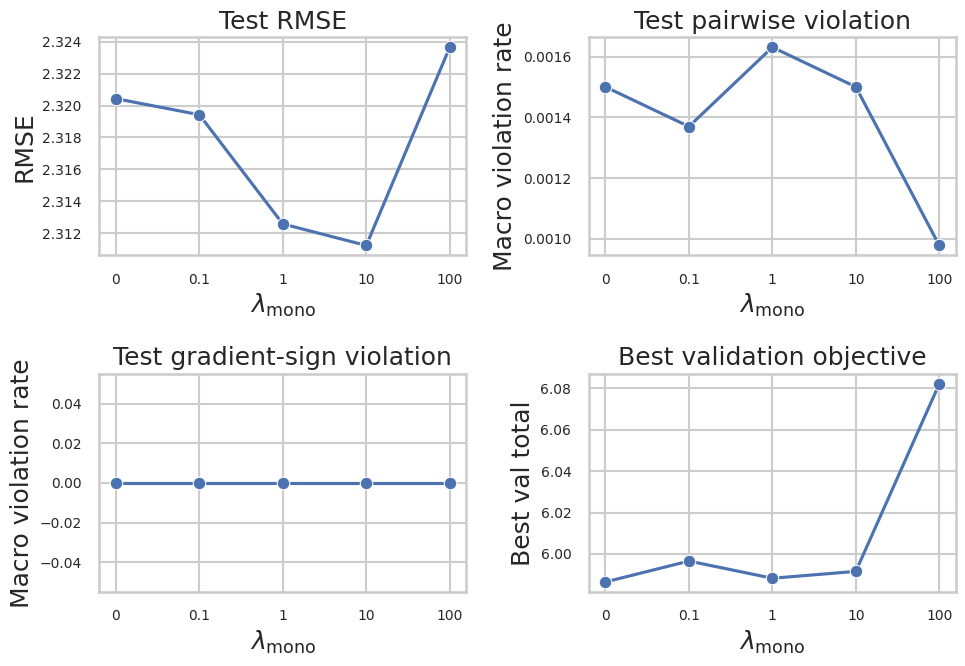

In [15]:
# Cell 15 - Main summary plots

plot_df = agg_df.copy()
plot_df["lambda_label"] = plot_df["lambda_mono"].map(lambda x: f"{x:g}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.ravel()

sns.lineplot(data=plot_df, x="lambda_label", y="test_rmse_mean", marker="o", ax=axes[0])
axes[0].set_title("Test RMSE")
axes[0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[0].set_ylabel("RMSE")

sns.lineplot(data=plot_df, x="lambda_label", y="test_pair_violation_macro_mean", marker="o", ax=axes[1])
axes[1].set_title("Test pairwise violation")
axes[1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[1].set_ylabel("Macro violation rate")

sns.lineplot(data=plot_df, x="lambda_label", y="test_grad_violation_macro_mean", marker="o", ax=axes[2])
axes[2].set_title("Test gradient-sign violation")
axes[2].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[2].set_ylabel("Macro violation rate")

sns.lineplot(data=plot_df, x="lambda_label", y="best_val_total_mean", marker="o", ax=axes[3])
axes[3].set_title("Best validation objective")
axes[3].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[3].set_ylabel("Best val total")

for ax in axes:
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_mono_summary.pdf", dpi=300, bbox_inches="tight")
plt.show()

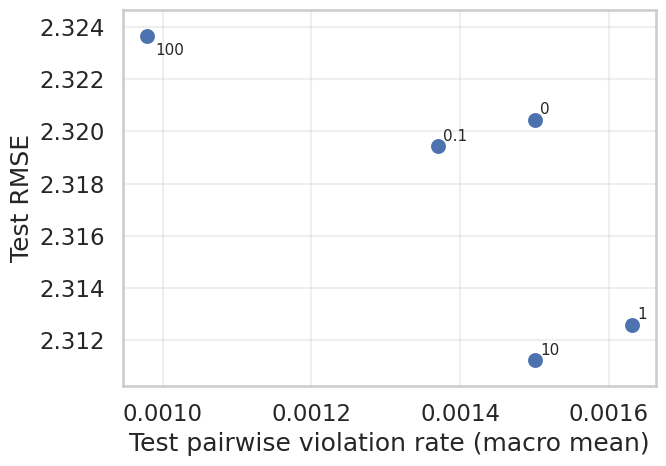

In [43]:
# Cell 16 - Accuracy-monotonicity trade-off plot

tradeoff_df = agg_df.copy()

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    tradeoff_df["test_pair_violation_macro_mean"],
    tradeoff_df["test_rmse_mean"],
    s=85,
)

# Slightly expand limits so edge labels fit comfortably
x = tradeoff_df["test_pair_violation_macro_mean"]
y = tradeoff_df["test_rmse_mean"]
xpad = 0.05 * (x.max() - x.min())
ypad = 0.08 * (y.max() - y.min())
ax.set_xlim(x.min() - xpad, x.max() + xpad)
ax.set_ylim(y.min() - ypad, y.max() + ypad)

# Manually tuned label offsets
offsets = {
    0.0: (4, 4),
    0.1: (4, 4),
    1.0: (4, 4),
    10.0: (4, 4),
    100.0: (6, -14),
}

for _, row in tradeoff_df.iterrows():
    label = row["lambda_mono"]
    ax.annotate(
        f"{label:g}",
        (row["test_pair_violation_macro_mean"], row["test_rmse_mean"]),
        xytext=offsets.get(label, (5, 5)),
        textcoords="offset points",
        fontsize=11,
    )

ax.set_xlabel("Test pairwise violation rate (macro mean)")
ax.set_ylabel("Test RMSE")
ax.set_title("")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_mono_tradeoff.pdf", dpi=300, bbox_inches="tight")
plt.show()

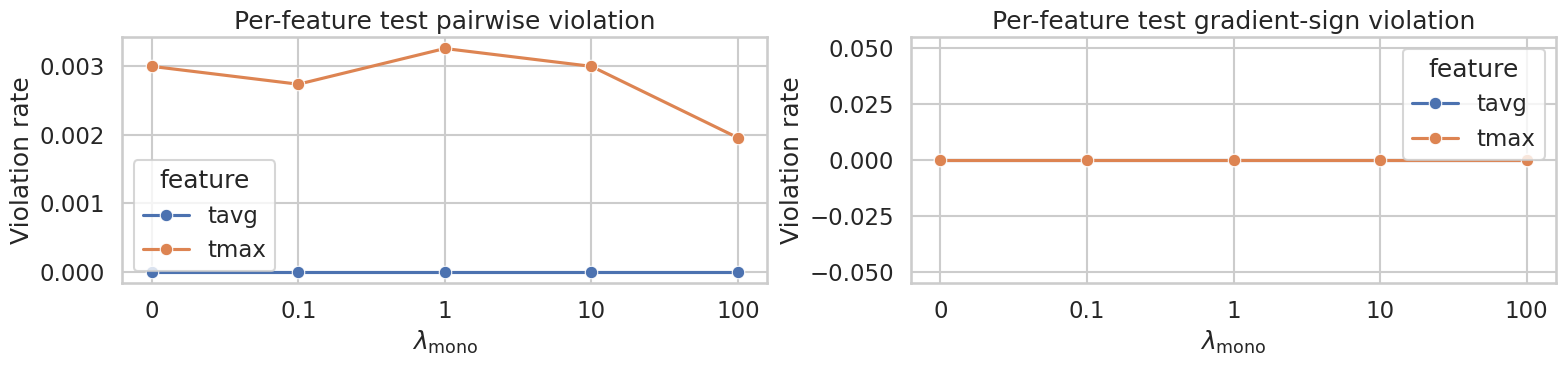

In [17]:
# Cell 17 - Per-feature monotonicity plots

feature_plot_rows = []
for _, row in agg_df.iterrows():
    lam = float(row["lambda_mono"])
    for feature in constrained_features:
        feature_plot_rows.append(
            {
                "lambda_mono": lam,
                "lambda_label": f"{lam:g}",
                "feature": feature,
                "test_pair_violation_mean": float(row[f"test_pair_violation_{feature}_mean"]),
                "test_grad_violation_mean": float(row[f"test_grad_violation_{feature}_mean"]),
            }
        )

feature_plot_df = pd.DataFrame(feature_plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharex=True)

sns.lineplot(
    data=feature_plot_df,
    x="lambda_label",
    y="test_pair_violation_mean",
    hue="feature",
    marker="o",
    ax=axes[0],
)
axes[0].set_title("Per-feature test pairwise violation")
axes[0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[0].set_ylabel("Violation rate")

sns.lineplot(
    data=feature_plot_df,
    x="lambda_label",
    y="test_grad_violation_mean",
    hue="feature",
    marker="o",
    ax=axes[1],
)
axes[1].set_title("Per-feature test gradient-sign violation")
axes[1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[1].set_ylabel("Violation rate")

plt.tight_layout()
plt.show()

In [18]:
# Cell 18 - Add after: Per-feature monotonicity plots
per_feature_long_table = (
    feature_plot_df
    .sort_values(["lambda_mono", "feature"])
    .reset_index(drop=True)
    .round(4)
)

per_feature_pair_table = (
    feature_plot_df
    .pivot(index="lambda_mono", columns="feature", values="test_pair_violation_mean")
    .sort_index()
    .round(4)
)

per_feature_grad_table = (
    feature_plot_df
    .pivot(index="lambda_mono", columns="feature", values="test_grad_violation_mean")
    .sort_index()
    .round(4)
)

print("Per-feature monotonicity summary (long form)")
display(per_feature_long_table)

print("Per-feature test pairwise violation rate")
display(per_feature_pair_table)

print("Per-feature test gradient-sign violation rate")
display(per_feature_grad_table)

Per-feature monotonicity summary (long form)


,lambda_mono,lambda_label,feature,test_pair_violation_mean,test_grad_violation_mean
0,0.0,0,tavg,0.0000,0.0
1,0.0,0,tmax,0.0030,0.0
2,0.1,0.1,tavg,0.0000,0.0
3,0.1,0.1,tmax,0.0027,0.0
4,1.0,1,tavg,0.0000,0.0
5,1.0,1,tmax,0.0033,0.0
6,10.0,10,tavg,0.0000,0.0
7,10.0,10,tmax,0.0030,0.0
8,100.0,100,tavg,0.0000,0.0
9,100.0,100,tmax,0.0020,0.0


Per-feature test pairwise violation rate


feature,tavg,tmax
lambda_mono,,
0.0,0.0,0.0030
0.1,0.0,0.0027
1.0,0.0,0.0033
10.0,0.0,0.0030
100.0,0.0,0.0020


Per-feature test gradient-sign violation rate


feature,tavg,tmax
lambda_mono,,
0.0,0.0,0.0
0.1,0.0,0.0
1.0,0.0,0.0
10.0,0.0,0.0
100.0,0.0,0.0


In [19]:
# Cell 19 - Compact summary table

summary_table = agg_df[
    [
        "lambda_mono",
        "best_val_total_mean",
        "test_rmse_mean",
        "test_rmse_std",
        "test_mae_mean",
        "test_pair_violation_macro_mean",
        "test_grad_violation_macro_mean",
    ]
].copy()

display(summary_table.round(4))

,lambda_mono,best_val_total_mean,test_rmse_mean,test_rmse_std,test_mae_mean,test_pair_violation_macro_mean,test_grad_violation_macro_mean
0,0.0,5.9864,2.3204,0.0119,1.8218,0.0015,0.0
1,0.1,5.9965,2.3194,0.0122,1.8214,0.0014,0.0
2,1.0,5.9882,2.3126,0.0051,1.8133,0.0016,0.0
3,10.0,5.9916,2.3112,0.0095,1.8141,0.0015,0.0
4,100.0,6.0823,2.3237,0.0072,1.8290,0.0010,0.0


In [20]:
# Cell 20 - Select the best nonzero lambda by lowest mean best validation total

positive_agg_df = agg_df.loc[agg_df["lambda_mono"] > 0].copy()

if len(positive_agg_df) == 0:
    best_lambda_by_val_total = 0.0
else:
    best_idx = positive_agg_df["best_val_total_mean"].idxmin()
    best_lambda_by_val_total = to_py_float(
        positive_agg_df.loc[best_idx, "lambda_mono"],
        name="best_lambda_by_val_total",
    )

print("Best nonzero lambda by mean best validation total:", best_lambda_by_val_total)

baseline_summary_row = agg_df.loc[agg_df["lambda_mono"] == 0.0].iloc[0]
best_summary_row = agg_df.loc[agg_df["lambda_mono"] == best_lambda_by_val_total].iloc[0]

comparison_table = pd.DataFrame(
    [
        {
            "model": "baseline (lambda=0)",
            "lambda_mono": 0.0,
            "test_rmse_mean": baseline_summary_row["test_rmse_mean"],
            "test_pair_violation_macro_mean": baseline_summary_row["test_pair_violation_macro_mean"],
            "test_grad_violation_macro_mean": baseline_summary_row["test_grad_violation_macro_mean"],
        },
        {
            "model": "best monotonic model",
            "lambda_mono": best_lambda_by_val_total,
            "test_rmse_mean": best_summary_row["test_rmse_mean"],
            "test_pair_violation_macro_mean": best_summary_row["test_pair_violation_macro_mean"],
            "test_grad_violation_macro_mean": best_summary_row["test_grad_violation_macro_mean"],
        },
    ]
)

display(comparison_table.round(4))

Best nonzero lambda by mean best validation total: 1.0


,model,lambda_mono,test_rmse_mean,test_pair_violation_macro_mean,test_grad_violation_macro_mean
0,baseline (lambda=0),0.0,2.3204,0.0015,0.0
1,best monotonic model,1.0,2.3126,0.0016,0.0


In [21]:
# Cell 21 - Debug check 3: inspect raw signed gradient distributions for baseline vs best monotonic model

assert 0.0 in selected_model_store, "Baseline model not stored."
assert best_lambda_by_val_total in selected_model_store, "Best monotonic model not stored."

for lam in [0.0, best_lambda_by_val_total]:
    model = selected_model_store[lam].to(device)
    print(f"\nLambda = {lam:g}")

    for feature in constrained_features:
        sg = get_signed_gradients(
            model,
            data.X_test,
            constrained_feature=feature,
            sign=sign_dict[feature],
            feature_cols=feature_cols,
            device=device,
        )

        print(
            f"{feature:>8s} | "
            f"min={sg.min(): .8f} | "
            f"p01={np.quantile(sg, 0.01): .8f} | "
            f"median={np.median(sg): .8f} | "
            f"mean={sg.mean(): .8f} | "
            f"neg_frac={np.mean(sg < 0.0): .8f}"
        )


Lambda = 0
    tavg | min= 2.70203304 | p01= 3.13790127 | median= 4.18027973 | mean= 4.37730671 | neg_frac= 0.00000000
    tmax | min= 1.36002588 | p01= 1.89851403 | median= 3.43948412 | mean= 3.44566838 | neg_frac= 0.00000000

Lambda = 1
    tavg | min= 2.86269212 | p01= 3.13826551 | median= 4.14645004 | mean= 4.36070484 | neg_frac= 0.00000000
    tmax | min= 1.38928139 | p01= 1.90599331 | median= 3.40424275 | mean= 3.43626864 | neg_frac= 0.00000000


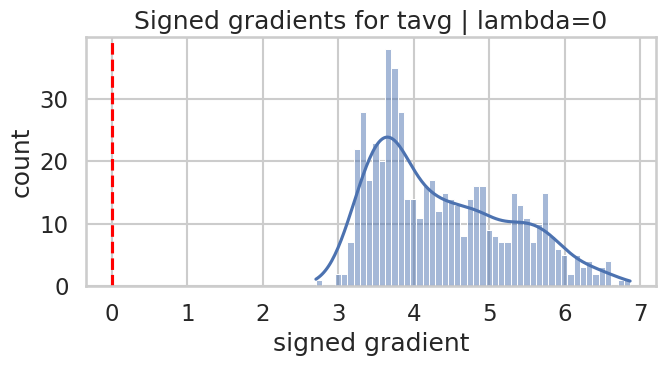

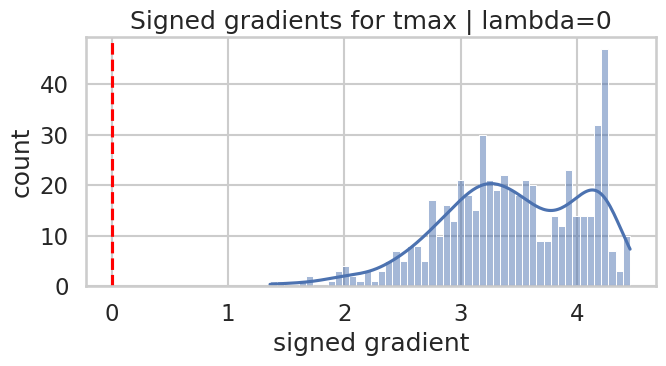

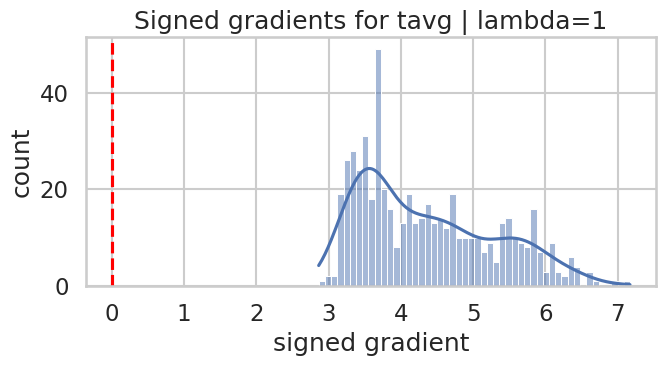

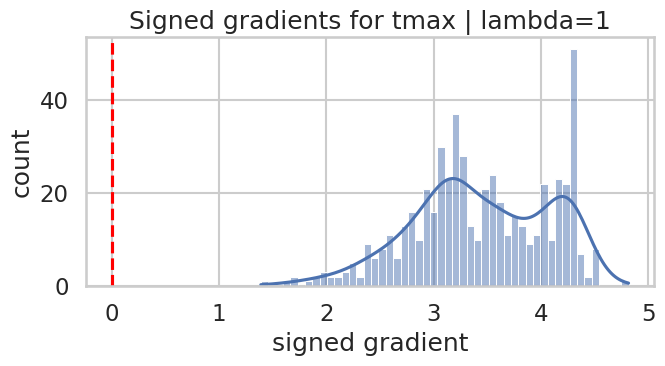

In [22]:
# Cell 22 - Debug check 4: histogram of signed gradients

for lam in [0.0, best_lambda_by_val_total]:
    model = selected_model_store[lam].to(device)

    for feature in constrained_features:
        sg = get_signed_gradients(
            model,
            data.X_test,
            constrained_feature=feature,
            sign=sign_dict[feature],
            feature_cols=feature_cols,
            device=device,
        )

        plt.figure(figsize=(7, 4))
        sns.histplot(sg, bins=50, kde=True)
        plt.axvline(0.0, color="red", linestyle="--")
        plt.title(f"Signed gradients for {feature} | lambda={lam:g}")
        plt.xlabel("signed gradient")
        plt.ylabel("count")
        plt.tight_layout()
        plt.show()

In [23]:
# Cell 23 - Debug check 5: finite-difference sanity check against autograd

rows_to_check = [0, len(data.X_test) // 2, len(data.X_test) - 1]

for lam in [0.0, best_lambda_by_val_total]:
    model = selected_model_store[lam].to(device)
    print(f"\nFinite-difference check for lambda={lam:g}")

    for feature in constrained_features:
        j = feature_cols.index(feature)

        sg = get_signed_gradients(
            model,
            data.X_test[rows_to_check],
            constrained_feature=feature,
            sign=sign_dict[feature],
            feature_cols=feature_cols,
            device=device,
        )

        print(f"\nFeature: {feature}")
        for local_idx, test_idx in enumerate(rows_to_check):
            fd = finite_difference_slope(
                model,
                data.X_test[test_idx],
                feature_idx=j,
                eps=1e-3,
                device=device,
            )

            print(
                f"test_idx={test_idx:4d} | "
                f"autograd_signed={sg[local_idx]: .8f} | "
                f"finite_diff_signed={sign_dict[feature] * fd: .8f}"
            )


Finite-difference check for lambda=0

Feature: tavg
test_idx=   0 | autograd_signed= 3.67508292 | finite_diff_signed= 3.67641449
test_idx= 274 | autograd_signed= 4.39029360 | finite_diff_signed= 4.39071655
test_idx= 548 | autograd_signed= 5.68476772 | finite_diff_signed= 5.68521023

Feature: tmax
test_idx=   0 | autograd_signed= 4.30010319 | finite_diff_signed= 4.30011749
test_idx= 274 | autograd_signed= 3.09105802 | finite_diff_signed= 3.09181213
test_idx= 548 | autograd_signed= 2.91363072 | finite_diff_signed= 2.91383266

Finite-difference check for lambda=1

Feature: tavg
test_idx=   0 | autograd_signed= 3.68005347 | finite_diff_signed= 3.68022919
test_idx= 274 | autograd_signed= 3.98476577 | finite_diff_signed= 3.95822525
test_idx= 548 | autograd_signed= 5.79488373 | finite_diff_signed= 5.79524040

Feature: tmax
test_idx=   0 | autograd_signed= 4.35201168 | finite_diff_signed= 4.35256958
test_idx= 274 | autograd_signed= 3.07989168 | finite_diff_signed= 3.06987762
test_idx= 548 | a

In [24]:
# Cell 24 - Debug check 6: negative-control gradient audit on unconstrained features

debug_features = ["tmin", "rand_noise"]

for feature in debug_features:
    if feature not in feature_cols:
        continue

    debug_metrics = compute_gradient_sign_audit(
        selected_model_store[0.0].to(device),
        data.X_test,
        split="test",
        constrained_feature=feature,
        sign=+1,  # arbitrary debugging direction
        feature_cols=feature_cols,
        device=device,
    )
    print(feature, debug_metrics)

tmin {'split': 'test', 'feature': 'tmin', 'sign': 1, 'n_points': 549, 'grad_violation_rate': 0.7395264116575592, 'mean_signed_gradient': -0.4363094920289104, 'median_signed_gradient': -0.4305100440979004, 'p05_signed_gradient': -1.4362677574157714, 'p95_signed_gradient': 0.4957977056503296}
rand_noise {'split': 'test', 'feature': 'rand_noise', 'sign': 1, 'n_points': 549, 'grad_violation_rate': 0.5027322404371585, 'mean_signed_gradient': -0.005312997813867524, 'median_signed_gradient': -0.0013404488563537598, 'p05_signed_gradient': -0.514995813369751, 'p95_signed_gradient': 0.449974536895752}


In [25]:
# Cell 25 - Save selected baseline and best-monotonic model checkpoints for the stored seed

model_export_dir = results_dir / "selected_models"
model_export_dir.mkdir(parents=True, exist_ok=True)

if 0.0 in selected_model_store:
    torch.save(
        selected_model_store[0.0].state_dict(),
        model_export_dir / f"lambda_0_seed_{selected_seed_for_store}.pt",
    )

if best_lambda_by_val_total in selected_model_store:
    torch.save(
        selected_model_store[best_lambda_by_val_total].state_dict(),
        model_export_dir / f"lambda_{best_lambda_by_val_total:g}_seed_{selected_seed_for_store}.pt",
    )

print("Saved selected model checkpoints to:", model_export_dir)

Saved selected model checkpoints to: <project root>/results/monotonicity_training/sweep_main/selected_models


Representative test rows:


/tmp/ipykernel_37036/1962200625.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,row_id,datetime,y_true,baseline_pred,tmin,tavg,tmax,prcp
221,221,2025-02-06 02:00:00,0.3,1.143,-0.2,0.8,1.7,0.0
461,461,2025-10-04 03:00:00,10.7,9.965,3.2,7.2,10.0,0.6
397,397,2025-08-01 03:00:00,23.2,23.290,17.4,20.8,25.4,10.3


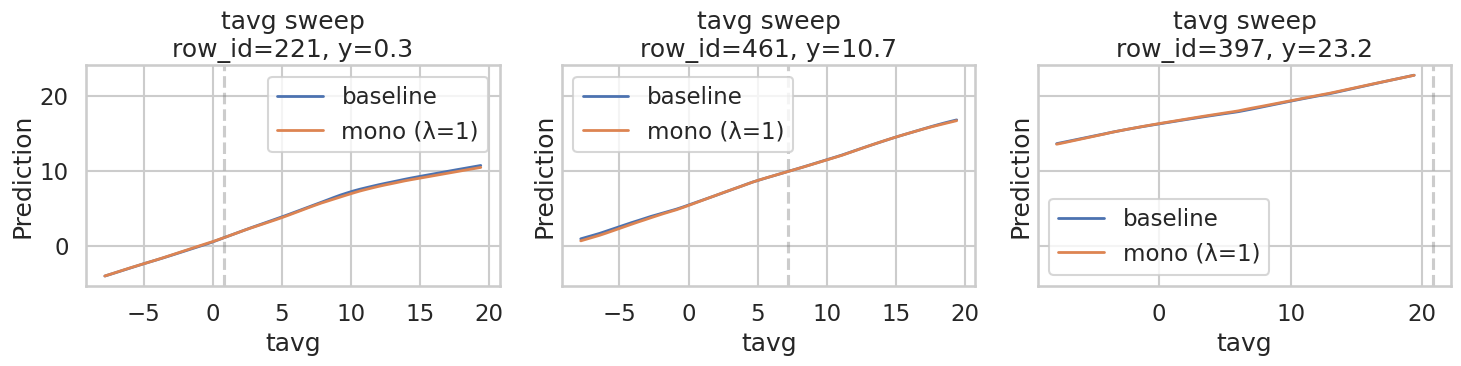

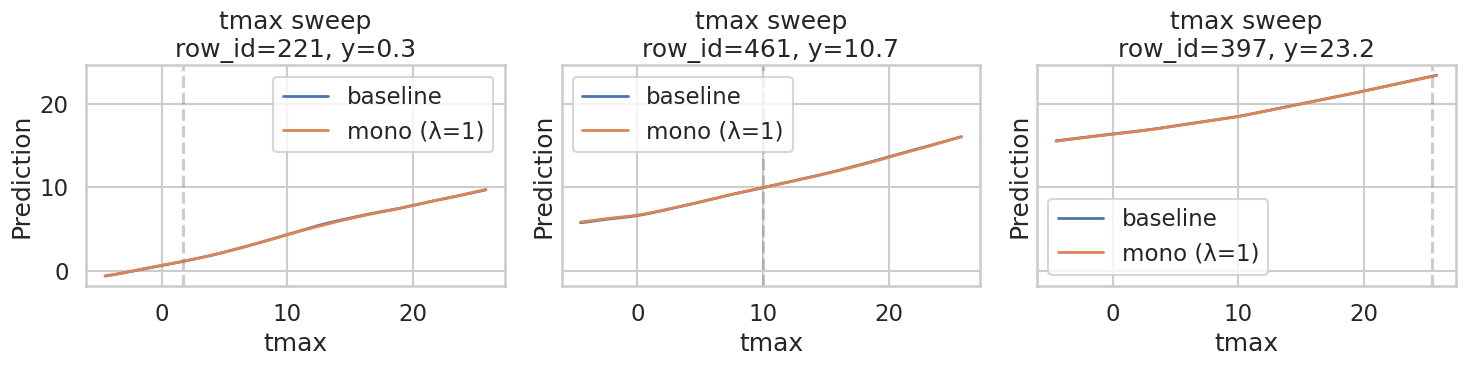

In [26]:
# Cell 26 - Qualitative comparison: baseline vs best monotonic model on counterfactual sweeps

assert 0.0 in selected_model_store, "Baseline model for selected seed was not stored."
assert best_lambda_by_val_total in selected_model_store, "Best monotonic model for selected seed was not stored."

baseline_model_for_plots = selected_model_store[0.0].to(device)
best_mono_model_for_plots = selected_model_store[best_lambda_by_val_total].to(device)

qual_test_df = data.test_df.copy().reset_index(drop=True)
qual_test_df["row_id"] = np.arange(len(qual_test_df))
qual_test_df["y_true"] = data.y_test.astype(float)
qual_test_df["baseline_pred"] = predict_numpy(baseline_model_for_plots, data.X_test, device=device)

for j, name in enumerate(feature_cols):
    qual_test_df[f"{name}__scaled"] = data.X_test[:, j]

rep_rows = select_representative_rows(
    qual_test_df,
    col="y_true",
    quantiles=(0.1, 0.5, 0.9),
)

print("Representative test rows:")
display(
    rep_rows[
        ["row_id", "datetime", "y_true", "baseline_pred", "tmin", "tavg", "tmax", "prcp"]
    ].round(3)
)

for feature_name in constrained_features:
    grid_orig = np.linspace(
        data.train_df[feature_name].quantile(0.05),
        data.train_df[feature_name].quantile(0.95),
        60,
    )

    fig, axes = plt.subplots(1, len(rep_rows), figsize=(5 * len(rep_rows), 4), sharey=True)
    if len(rep_rows) == 1:
        axes = [axes]

    for ax, (_, base_row) in zip(axes, rep_rows.iterrows()):
        cf_base = make_counterfactual_sweep_df(
            baseline_model_for_plots,
            base_row=base_row,
            feature_name=feature_name,
            grid_orig=grid_orig,
            feature_cols=feature_cols,
            scaler=data.scaler,
            device=device,
        )
        cf_mono = make_counterfactual_sweep_df(
            best_mono_model_for_plots,
            base_row=base_row,
            feature_name=feature_name,
            grid_orig=grid_orig,
            feature_cols=feature_cols,
            scaler=data.scaler,
            device=device,
        )

        ax.plot(cf_base["feature_value_orig"], cf_base["prediction"], label="baseline", linewidth=2)
        ax.plot(cf_mono["feature_value_orig"], cf_mono["prediction"], label=f"mono (λ={best_lambda_by_val_total:g})", linewidth=2)
        ax.axvline(float(base_row[feature_name]), color="gray", linestyle="--", alpha=0.4)
        ax.set_title(
            f"{feature_name} sweep\nrow_id={int(base_row['row_id'])}, y={base_row['y_true']:.1f}"
        )
        ax.set_xlabel(feature_name)
        ax.set_ylabel("Prediction")
        ax.legend()

    plt.tight_layout()
    plt.show()

In [27]:
# Cell 27 - Add after: Qualitative comparison: baseline vs best monotonic model on counterfactual sweeps

def summarize_counterfactual_curve(cf_df, sign=+1, tol=1e-8):
    x = cf_df["feature_value_orig"].to_numpy(dtype=float)
    y = cf_df["prediction"].to_numpy(dtype=float)
    signed_steps = sign * np.diff(y)

    return {
        "grid_low": float(x[0]),
        "grid_mid": float(x[len(x) // 2]),
        "grid_high": float(x[-1]),
        "pred_low": float(y[0]),
        "pred_mid": float(y[len(y) // 2]),
        "pred_high": float(y[-1]),
        "delta_high_minus_low": float(y[-1] - y[0]),
        "monotone_on_grid": bool(np.all(signed_steps >= -tol)),
        "n_wrong_steps": int(np.sum(signed_steps < -tol)),
    }

counterfactual_summary_rows = []

for feature_name in constrained_features:
    grid_orig = np.linspace(
        data.train_df[feature_name].quantile(0.05),
        data.train_df[feature_name].quantile(0.95),
        21,
    )

    for _, base_row in rep_rows.iterrows():
        for model_name, model_obj in {
            "baseline": baseline_model_for_plots,
            f"mono_lambda_{best_lambda_by_val_total:g}": best_mono_model_for_plots,
        }.items():
            cf = make_counterfactual_sweep_df(
                model_obj,
                base_row=base_row,
                feature_name=feature_name,
                grid_orig=grid_orig,
                feature_cols=feature_cols,
                scaler=data.scaler,
                device=device,
            )

            row = {
                "row_id": int(base_row["row_id"]),
                "y_true": float(base_row["y_true"]),
                "feature": feature_name,
                "model": model_name,
            }
            row.update(summarize_counterfactual_curve(cf, sign=int(sign_dict[feature_name])))
            counterfactual_summary_rows.append(row)

counterfactual_summary_df = (
    pd.DataFrame(counterfactual_summary_rows)
    .sort_values(["feature", "row_id", "model"])
    .reset_index(drop=True)
    .round(4)
)

display(counterfactual_summary_df)

,row_id,y_true,feature,model,grid_low,grid_mid,grid_high,pred_low,pred_mid,pred_high,delta_high_minus_low,monotone_on_grid,n_wrong_steps
0,221,0.3,tavg,baseline,-7.800,5.8000,19.4,-3.9345,4.4563,10.7614,14.6959,True,0
1,221,0.3,tavg,mono_lambda_1,-7.800,5.8000,19.4,-3.9276,4.3675,10.5032,14.4307,True,0
2,397,23.2,tavg,baseline,-7.800,5.8000,19.4,13.6627,17.8510,22.7640,9.1013,True,0
3,397,23.2,tavg,mono_lambda_1,-7.800,5.8000,19.4,13.5849,17.9523,22.7521,9.1672,True,0
4,461,10.7,tavg,baseline,-7.800,5.8000,19.4,1.0128,9.2057,16.8194,15.8065,True,0
5,461,10.7,tavg,mono_lambda_1,-7.800,5.8000,19.4,0.7429,9.2137,16.7193,15.9764,True,0
6,221,0.3,tmax,baseline,-4.525,10.6375,25.8,-0.6075,4.6400,9.6983,10.3057,True,0
7,221,0.3,tmax,mono_lambda_1,-4.525,10.6375,25.8,-0.6113,4.6071,9.7417,10.3530,True,0
8,397,23.2,tmax,baseline,-4.525,10.6375,25.8,15.5711,18.6721,23.4206,7.8495,True,0
9,397,23.2,tmax,mono_lambda_1,-4.525,10.6375,25.8,15.5183,18.6524,23.3947,7.8764,True,0


## Interpretation guide

When reading the results:

- lower **test RMSE** is better for predictive performance,
- lower **pairwise violation rate** means better monotonic alignment on the saved local comparison pairs,
- lower **gradient-sign violation rate** means better local differential monotonicity,
- lower **best validation total** means a better compromise under the chosen training objective.

A useful outcome for RQ2 is not necessarily a large RMSE improvement.  
If the baseline is already fairly monotone, a successful result may instead be:

- similar RMSE,
- lower monotonicity violations,
- and more controlled counterfactual behaviour.

## Negative-control monotonicity experiments

The main monotonicity experiments used only the feature-direction pairs that passed the audit in notebook 07.  
To confirm that the monotonicity regularizer is **actually active** and not merely inert, this section runs a small set of deliberately poor monotonic priors.

### Goal of these sanity checks
We want to verify that if we impose a **bad** monotonic rule, training responds to it.

### Negative-control specifications
The following kinds of bad priors are useful:

- **wrong-sign constraints** on otherwise good features  
  for example, forcing `tavg` or `tmax` to be nonincreasing instead of nondecreasing,

- **weak or low-confidence constraints**  
  such as `tmin` nondecreasing, which notebook 07 rejected.

### How to read the results
For each negative-control model, we evaluate:

1. **task performance**  
   RMSE and MAE on the true prediction task,

2. **constraint satisfaction under the imposed bad prior**  
   to see whether the model is responding to that prior,

3. **correct-sign monotonicity metrics under the original main specification**  
   to see whether bad priors degrade the desired monotonic behavior.

A useful sanity-check outcome is:

- the model becomes more compatible with the **bad imposed rule**,
- while becoming worse under the **correct interpretation** or in predictive accuracy.

In [28]:
#  Cell 28 - Negative-control experiment setup

available_pair_features = sorted(manifest_df["feature"].astype(str).unique().tolist())

all_train_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="train",
    features=available_pair_features,
)
all_val_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="val",
    features=available_pair_features,
)
all_test_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="test",
    features=available_pair_features,
)

print("Available pair-artifact features:", available_pair_features)

negative_control_specs: list[dict] = [
    {
        "spec_name": "wrong_sign_tavg",
        "description": "Deliberately wrong sign: force tavg to be nonincreasing.",
        "features": ["tavg"],
        "sign_dict": {"tavg": -1},
    },
    {
        "spec_name": "wrong_sign_tmax",
        "description": "Deliberately wrong sign: force tmax to be nonincreasing.",
        "features": ["tmax"],
        "sign_dict": {"tmax": -1},
    },
]

# Optional weak-prior control, only if pair artifacts exist
if "tmin" in available_pair_features:
    negative_control_specs.append(
        {
            "spec_name": "weak_prior_tmin",
            "description": "Low-confidence prior from notebook 07: force tmin to be nondecreasing.",
            "features": ["tmin"],
            "sign_dict": {"tmin": +1},
        }
    )

# Optional regime-dependent control, only if pair artifacts exist
if "prcp" in available_pair_features:
    negative_control_specs.append(
        {
            "spec_name": "weak_prior_prcp",
            "description": "Regime-dependent prior from notebook 07: force prcp to be nonincreasing.",
            "features": ["prcp"],
            "sign_dict": {"prcp": -1},
        }
    )

negative_control_df = pd.DataFrame(
    [
        {
            "spec_name": spec["spec_name"],
            "description": spec["description"],
            "features": ", ".join(spec["features"]),
            "sign_dict": str(spec["sign_dict"]),
        }
        for spec in negative_control_specs
    ]
)

display(negative_control_df)

# Small sweep only; this is a sanity check, not the main experiment.
negative_lambda_values = list(lambda_values)
negative_seeds = [0, 1, 2, 3, 4]
selected_negative_lambda_for_plots = 10.0

print("negative_lambda_values:", negative_lambda_values)
print("negative_seeds:", negative_seeds)
print("selected_negative_lambda_for_plots:", selected_negative_lambda_for_plots)

Available pair-artifact features: ['prcp', 'tavg', 'tmax', 'tmin']


,spec_name,description,features,sign_dict
0,wrong_sign_tavg,Deliberately wrong sign: force tavg to be noni...,tavg,{'tavg': -1}
1,wrong_sign_tmax,Deliberately wrong sign: force tmax to be noni...,tmax,{'tmax': -1}
2,weak_prior_tmin,Low-confidence prior from notebook 07: force t...,tmin,{'tmin': 1}
3,weak_prior_prcp,Regime-dependent prior from notebook 07: force...,prcp,{'prcp': -1}


negative_lambda_values: [0.0, 0.1, 1.0, 10.0, 100.0]
negative_seeds: [0, 1, 2, 3, 4]
selected_negative_lambda_for_plots: 10.0


In [29]:
# Cell 29 - Helper to subset pair dictionaries by feature

def subset_pair_index_dict(
    full_pair_dict: dict[str, np.ndarray],
    features: list[str],
) -> dict[str, np.ndarray]:
    return {
        feature: full_pair_dict[feature]
        for feature in features
        if feature in full_pair_dict
    }

In [30]:
# Cell 30 - Run the negative-control experiments

negative_records: list[dict[str, object]] = []
negative_history_frames: list[pd.DataFrame] = []
negative_model_store: dict[tuple[str, float], nn.Module] = {}

for spec in negative_control_specs:
    spec_name = str(spec["spec_name"])
    spec_desc = str(spec["description"])
    spec_features = list(spec["features"])
    spec_sign_dict = {str(k): int(v) for k, v in spec["sign_dict"].items()}

    exp_train_pair_dict = subset_pair_index_dict(all_train_pair_index_dict, spec_features)
    exp_val_pair_dict = subset_pair_index_dict(all_val_pair_index_dict, spec_features)
    exp_test_pair_dict = subset_pair_index_dict(all_test_pair_index_dict, spec_features)

    print(f"\n=== Negative control: {spec_name} ===")
    print(spec_desc)
    print("Features:", spec_features)
    print("Signs:", spec_sign_dict)

    for lam in negative_lambda_values:
        for seed in negative_seeds:
            print(f"Running negative control: spec={spec_name}, lambda_mono={lam:g}, seed={seed}")
            set_seed(seed)

            model = instantiate_model(input_dim=len(feature_cols))

            model, history = train_monotonic_regressor(
                model,
                train_loader=train_loader,
                val_loader=val_loader,
                X_train_np=data.X_train,
                X_val_np=data.X_val,
                train_pair_index_dict=exp_train_pair_dict,
                val_pair_index_dict=exp_val_pair_dict,
                sign_dict=spec_sign_dict,
                config=config,
                lambda_mono=float(lam),
                device=device,
                mono_margin=mono_margin,
                mono_reduction=mono_reduction,
                max_pairs_per_feature_train=max_pairs_per_feature_train,
                max_pairs_per_feature_eval=max_pairs_per_feature_eval,
                seed=seed,
            )

            hist_df = pd.DataFrame(history)
            hist_df["spec_name"] = spec_name
            hist_df["lambda_mono"] = float(lam)
            hist_df["seed"] = float(seed)
            negative_history_frames.append(hist_df)

            best_idx = hist_df["val_total_loss"].astype(float).idxmin()
            best_row = hist_df.loc[best_idx]

            # Evaluation under the imposed bad/weak prior
            exp_test_eval = evaluate_monotonic_suite(
                model,
                data.X_test,
                data.y_test,
                split_name="test",
                pair_index_dict=exp_test_pair_dict,
                sign_dict=spec_sign_dict,
                feature_cols=feature_cols,
                device=device,
            )

            # Evaluation under the original main/correct RQ2 specification
            main_test_eval = evaluate_monotonic_suite(
                model,
                data.X_test,
                data.y_test,
                split_name="test",
                pair_index_dict=test_pair_index_dict,
                sign_dict=sign_dict,
                feature_cols=feature_cols,
                device=device,
            )

            # Standard predictive metrics, same as in the main sweep
            test_reg = eval_loader_reg(model, test_loader, device=device)

            record: dict[str, object] = {
                "spec_name": spec_name,
                "lambda_mono": float(lam),
                "seed": float(seed),
                "n_epochs_trained": float(len(hist_df)),
                "best_epoch": to_py_float(best_row["epoch"], name="best_epoch"),
                "best_val_task": to_py_float(best_row["val_task_loss"], name="best_val_task"),
                "best_val_mono": to_py_float(best_row["val_mono_loss"], name="best_val_mono"),
                "best_val_total": to_py_float(best_row["val_total_loss"], name="best_val_total"),
                "test_mse": to_py_float(test_reg["mse"], name="test_mse"),
                "test_rmse": to_py_float(test_reg["rmse"], name="test_rmse"),
                "test_mae": to_py_float(test_reg["mae"], name="test_mae"),
            }

            record.update(prefix_dict(exp_test_eval, "exp_test"))
            record.update(prefix_dict(main_test_eval, "main_test"))

            negative_records.append(record)

            if seed == selected_seed_for_store and lam == selected_negative_lambda_for_plots:
                negative_model_store[(spec_name, float(lam))] = copy.deepcopy(model).to("cpu")

negative_sweep_df = pd.DataFrame(negative_records)
negative_history_df = pd.concat(negative_history_frames, ignore_index=True)




=== Negative control: wrong_sign_tavg ===
Deliberately wrong sign: force tavg to be nonincreasing.
Features: ['tavg']
Signs: {'tavg': -1}
Running negative control: spec=wrong_sign_tavg, lambda_mono=0, seed=0
Epoch 001 | train_task=176.7362 train_mono=0.2054 train_total=176.7362 | val_task=155.3286 val_mono=0.2376 val_total=155.3286
Epoch 010 | train_task=6.1922 train_mono=3.0916 train_total=6.1922 | val_task=6.7509 val_mono=3.5801 val_total=6.7509
Epoch 020 | train_task=5.8585 train_mono=3.4738 train_total=5.8585 | val_task=6.2420 val_mono=3.8453 val_total=6.2420
Epoch 030 | train_task=5.6236 train_mono=3.7386 train_total=5.6236 | val_task=6.0566 val_mono=3.9957 val_total=6.0566
Epoch 040 | train_task=5.5313 train_mono=3.9365 train_total=5.5313 | val_task=6.0031 val_mono=4.0864 val_total=6.0031
Early stopping at epoch 048 | best_val_total=5.973720
Running negative control: spec=wrong_sign_tavg, lambda_mono=0, seed=1
Epoch 001 | train_task=173.1674 train_mono=0.2560 train_total=173.167

In [31]:
# Cell 31 - Optional replacement for full negative-control raw display
print("\nNegative-control raw results:")

negative_run_preview = (
    negative_sweep_df[
        [
            "spec_name",
            "lambda_mono",
            "seed",
            "test_rmse",
            "exp_test_pair_violation_macro",
            "main_test_pair_violation_macro",
            "main_test_grad_violation_macro",
        ]
    ]
    .sort_values(["spec_name", "lambda_mono", "seed"])
    .reset_index(drop=True)
    .round(4)
)

display(negative_run_preview)


Negative-control raw results:


,spec_name,lambda_mono,seed,test_rmse,exp_test_pair_violation_macro,main_test_pair_violation_macro,main_test_grad_violation_macro
0,weak_prior_prcp,0.0,0.0,2.3235,0.3772,0.0013,0.0000
1,weak_prior_prcp,0.0,1.0,2.3391,0.4082,0.0023,0.0000
2,weak_prior_prcp,0.0,2.0,2.3173,0.3815,0.0003,0.0000
3,weak_prior_prcp,0.0,3.0,2.3149,0.3921,0.0020,0.0000
4,weak_prior_prcp,0.0,4.0,2.3074,0.3985,0.0016,0.0000
...,...,...,...,...,...,...,...
95,wrong_sign_tmax,100.0,0.0,3.7281,0.3477,0.5208,0.5000
96,wrong_sign_tmax,100.0,1.0,3.6747,0.3242,0.5593,0.5000
97,wrong_sign_tmax,100.0,2.0,3.6697,0.3425,0.5311,0.5000
98,wrong_sign_tmax,100.0,3.0,3.7011,0.3379,0.5219,0.5082


In [32]:
# Cell 32 - Save negative-control results

negative_results_dir = results_dir / "negative_controls"
negative_results_dir.mkdir(parents=True, exist_ok=True)

negative_sweep_df.to_csv(negative_results_dir / "runs_raw.csv", index=False)
negative_history_df.to_csv(negative_results_dir / "history_raw.csv", index=False)

negative_config_payload = {
    "negative_control_specs": negative_control_specs,
    "negative_lambda_values": [float(v) for v in negative_lambda_values],
    "negative_seeds": [int(s) for s in negative_seeds],
    "selected_negative_lambda_for_plots": float(selected_negative_lambda_for_plots),
}
with open(negative_results_dir / "config.json", "w") as fh:
    json.dump(negative_config_payload, fh, indent=2)

print("Saved negative-control outputs to:", negative_results_dir)

Saved negative-control outputs to: <project root>/results/monotonicity_training/sweep_main/negative_controls


In [33]:
# Cell 33 - Aggregate negative-control results

negative_agg_spec = {
    "best_val_total_mean": ("best_val_total", "mean"),
    "best_val_total_std": ("best_val_total", "std"),
    "test_rmse_mean": ("test_rmse", "mean"),
    "test_rmse_std": ("test_rmse", "std"),
    "test_mae_mean": ("test_mae", "mean"),

    # Metrics under the imposed bad prior
    "exp_test_pair_violation_macro_mean": ("exp_test_pair_violation_macro", "mean"),
    "exp_test_pair_violation_macro_std": ("exp_test_pair_violation_macro", "std"),
    "exp_test_grad_violation_macro_mean": ("exp_test_grad_violation_macro", "mean"),

    # Metrics under the original correct main RQ2 interpretation
    "main_test_pair_violation_macro_mean": ("main_test_pair_violation_macro", "mean"),
    "main_test_pair_violation_macro_std": ("main_test_pair_violation_macro", "std"),
    "main_test_grad_violation_macro_mean": ("main_test_grad_violation_macro", "mean"),
}

negative_agg_df = (
    negative_sweep_df
    .groupby(["spec_name", "lambda_mono"])
    .agg(**negative_agg_spec)
    .reset_index()
)

negative_agg_df.to_csv(negative_results_dir / "summary.csv", index=False)

print("Negative-control aggregate summary:")
display(negative_agg_df.round(4))

Negative-control aggregate summary:


,spec_name,lambda_mono,best_val_total_mean,best_val_total_std,test_rmse_mean,test_rmse_std,test_mae_mean,exp_test_pair_violation_macro_mean,exp_test_pair_violation_macro_std,exp_test_grad_violation_macro_mean,main_test_pair_violation_macro_mean,main_test_pair_violation_macro_std,main_test_grad_violation_macro_mean
0,weak_prior_prcp,0.0,5.9864,0.0395,2.3204,0.0119,1.8218,0.3915,0.0126,0.3020,0.0015,0.0008,0.0000
1,weak_prior_prcp,0.1,6.0590,0.0373,2.3206,0.0118,1.8214,0.3803,0.0118,0.2856,0.0015,0.0008,0.0000
2,weak_prior_prcp,1.0,6.6167,0.0324,2.3270,0.0062,1.8255,0.3141,0.0086,0.0969,0.0024,0.0007,0.0000
3,weak_prior_prcp,10.0,9.4004,0.1044,2.3954,0.0113,1.8784,0.1928,0.0059,0.0200,0.0048,0.0013,0.0000
4,weak_prior_prcp,100.0,18.3021,0.1368,2.5185,0.0053,1.9816,0.0930,0.0061,0.0044,0.0115,0.0008,0.0000
5,weak_prior_tmin,0.0,5.9864,0.0395,2.3204,0.0119,1.8218,0.2425,0.0041,0.8714,0.0015,0.0008,0.0000
6,weak_prior_tmin,0.1,6.0311,0.0492,2.3153,0.0048,1.8171,0.2333,0.0042,0.8244,0.0020,0.0009,0.0000
7,weak_prior_tmin,1.0,6.4650,0.0588,2.3242,0.0041,1.8261,0.1804,0.0042,0.2754,0.0037,0.0013,0.0000
8,weak_prior_tmin,10.0,7.8421,0.0669,2.3957,0.0203,1.8773,0.0897,0.0033,0.0000,0.0095,0.0007,0.0000
9,weak_prior_tmin,100.0,10.3256,0.1266,2.5130,0.0296,1.9674,0.0371,0.0017,0.0000,0.0258,0.0037,0.0031


### How to interpret the negative-control summary

For each negative-control specification:

- **`exp_test_*` metrics** evaluate the model under the **bad imposed rule**.  
  If these improve, that means the regularizer is actively pushing the model toward the bad prior.

- **`main_test_*` metrics** evaluate the same trained model under the **correct original monotonic interpretation**.  
  If these get worse, that means the bad prior is damaging the desired behavior.

This is exactly what we want from a sanity check:
the model should respond to the regularizer, even when the prior is bad.

In [34]:
# Cell 34 - Compact negative-control summary table

negative_summary_table = negative_agg_df[
    [
        "spec_name",
        "lambda_mono",
        "test_rmse_mean",
        "exp_test_pair_violation_macro_mean",
        "main_test_pair_violation_macro_mean",
        "main_test_grad_violation_macro_mean",
    ]
].copy()

display(negative_summary_table.round(4))

,spec_name,lambda_mono,test_rmse_mean,exp_test_pair_violation_macro_mean,main_test_pair_violation_macro_mean,main_test_grad_violation_macro_mean
0,weak_prior_prcp,0.0,2.3204,0.3915,0.0015,0.0000
1,weak_prior_prcp,0.1,2.3206,0.3803,0.0015,0.0000
2,weak_prior_prcp,1.0,2.3270,0.3141,0.0024,0.0000
3,weak_prior_prcp,10.0,2.3954,0.1928,0.0048,0.0000
4,weak_prior_prcp,100.0,2.5185,0.0930,0.0115,0.0000
5,weak_prior_tmin,0.0,2.3204,0.2425,0.0015,0.0000
6,weak_prior_tmin,0.1,2.3153,0.2333,0.0020,0.0000
7,weak_prior_tmin,1.0,2.3242,0.1804,0.0037,0.0000
8,weak_prior_tmin,10.0,2.3957,0.0897,0.0095,0.0000
9,weak_prior_tmin,100.0,2.5130,0.0371,0.0258,0.0031


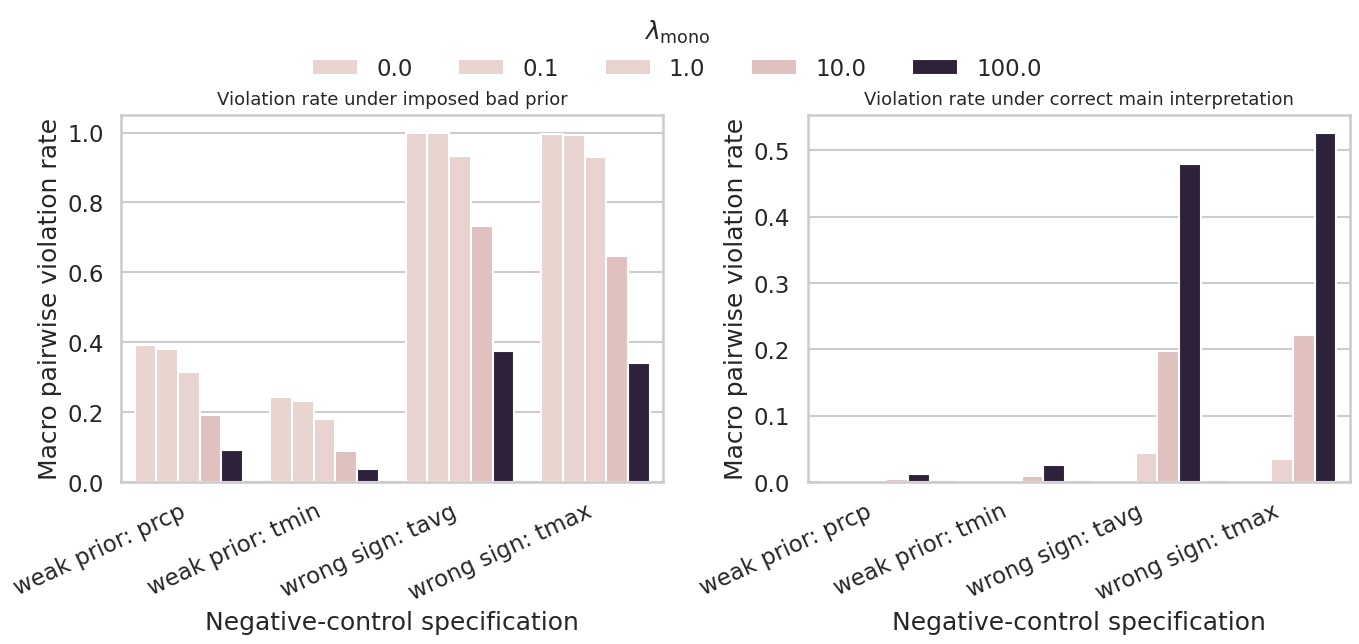

In [45]:
# Cell 35 - Plot: imposed bad-prior satisfaction vs correct main monotonicity

# Cell 35 - Plot: imposed bad-prior satisfaction vs correct main monotonicity

plot_df = negative_agg_df.copy()

# Optional: cleaner x-axis labels
pretty_spec = {
    "weak_prior_prcp": "weak prior: prcp",
    "weak_prior_tmin": "weak prior: tmin",
    "wrong_sign_tavg": "wrong sign: tavg",
    "wrong_sign_tmax": "wrong sign: tmax",
}
plot_df["spec_name_pretty"] = plot_df["spec_name"].map(pretty_spec).fillna(plot_df["spec_name"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=False)

# Left panel
sns.barplot(
    data=plot_df,
    x="spec_name_pretty",
    y="exp_test_pair_violation_macro_mean",
    hue="lambda_mono",
    ax=axes[0],
)

axes[0].set_title("Violation rate under imposed bad prior", fontsize=13, pad=8)
axes[0].set_xlabel("Negative-control specification")
axes[0].set_ylabel("Macro pairwise violation rate")
axes[0].tick_params(axis="x", rotation=25)
for tick in axes[0].get_xticklabels():
    tick.set_ha("right")

# Right panel
sns.barplot(
    data=plot_df,
    x="spec_name_pretty",
    y="main_test_pair_violation_macro_mean",
    hue="lambda_mono",
    ax=axes[1],
)

axes[1].set_title("Violation rate under correct main interpretation", fontsize=13, pad=8)
axes[1].set_xlabel("Negative-control specification")
axes[1].set_ylabel("Macro pairwise violation rate")
axes[1].tick_params(axis="x", rotation=25)
for tick in axes[1].get_xticklabels():
    tick.set_ha("right")

# Remove individual legends
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend_.remove()
axes[1].legend_.remove()

# Add one shared legend above the panels
fig.legend(
    handles,
    labels,
    title=r"$\lambda_{\mathrm{mono}}$",
    loc="upper center",
    ncol=len(labels),
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig("../docs/figures/ch5_mono_negative_controls.pdf", dpi=300, bbox_inches="tight")
plt.show()

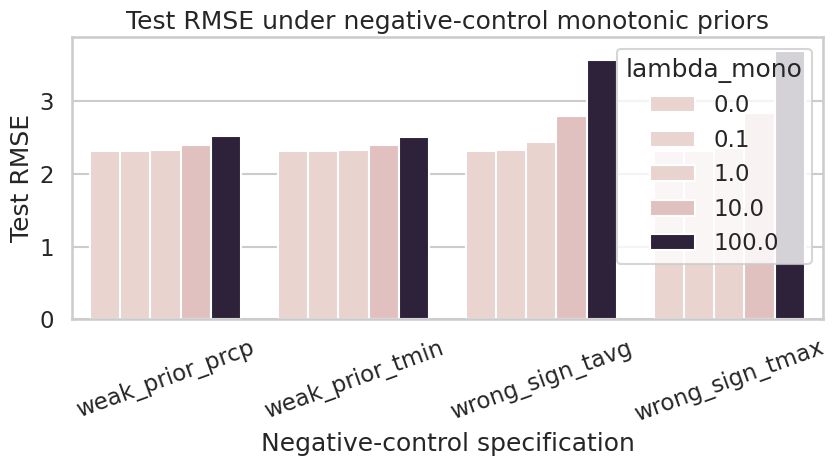

In [36]:
# Cell 36 - Plot: predictive accuracy under negative controls

plt.figure(figsize=(9, 5))
sns.barplot(
    data=negative_agg_df,
    x="spec_name",
    y="test_rmse_mean",
    hue="lambda_mono",
)
plt.title("Test RMSE under negative-control monotonic priors")
plt.xlabel("Negative-control specification")
plt.ylabel("Test RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Qualitative sanity-check plots

The next cell plots local counterfactual sweeps for the stored negative-control models.

These plots are especially useful for the wrong-sign constraints:
if the regularizer is active, the response curve may flatten or bend in the wrong direction
relative to the correct monotonic interpretation.

Representative test rows for negative-control plots:


/tmp/ipykernel_37036/779624524.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,row_id,datetime,y_true,baseline_pred,tmin,tavg,tmax,prcp
221,221,2025-02-06 02:00:00,0.3,1.143,-0.2,0.8,1.7,0.0
461,461,2025-10-04 03:00:00,10.7,9.965,3.2,7.2,10.0,0.6
397,397,2025-08-01 03:00:00,23.2,23.290,17.4,20.8,25.4,10.3


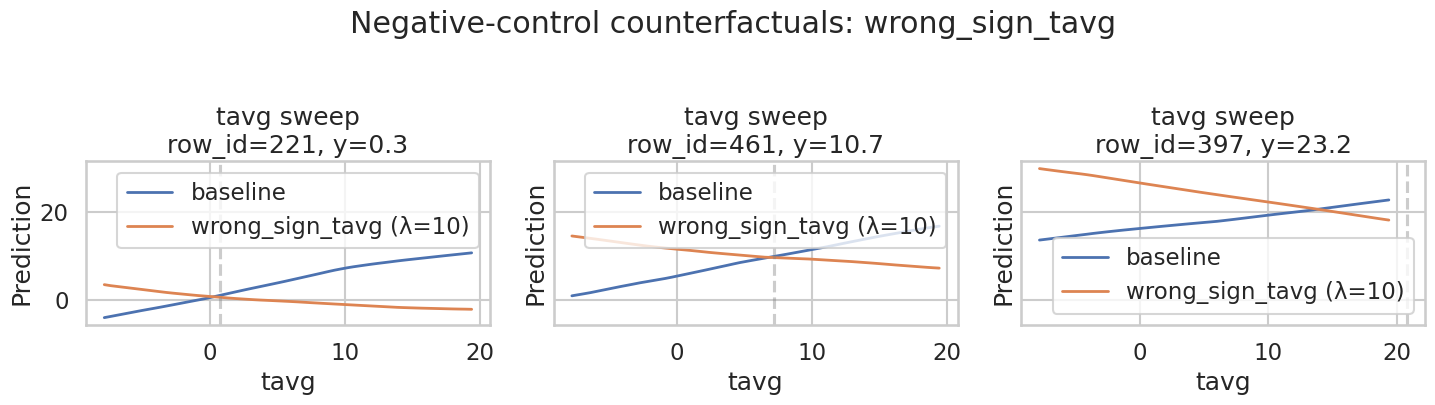

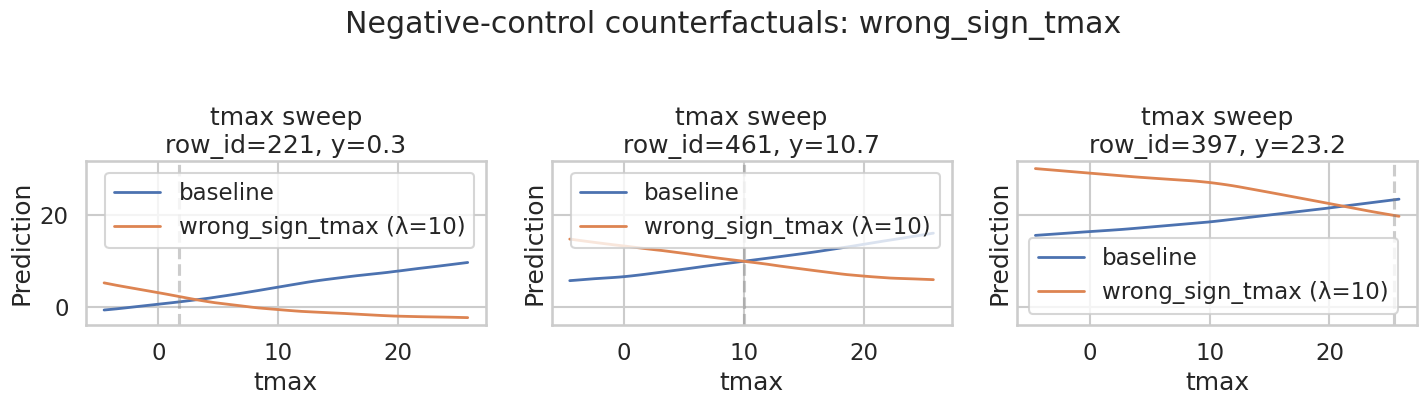

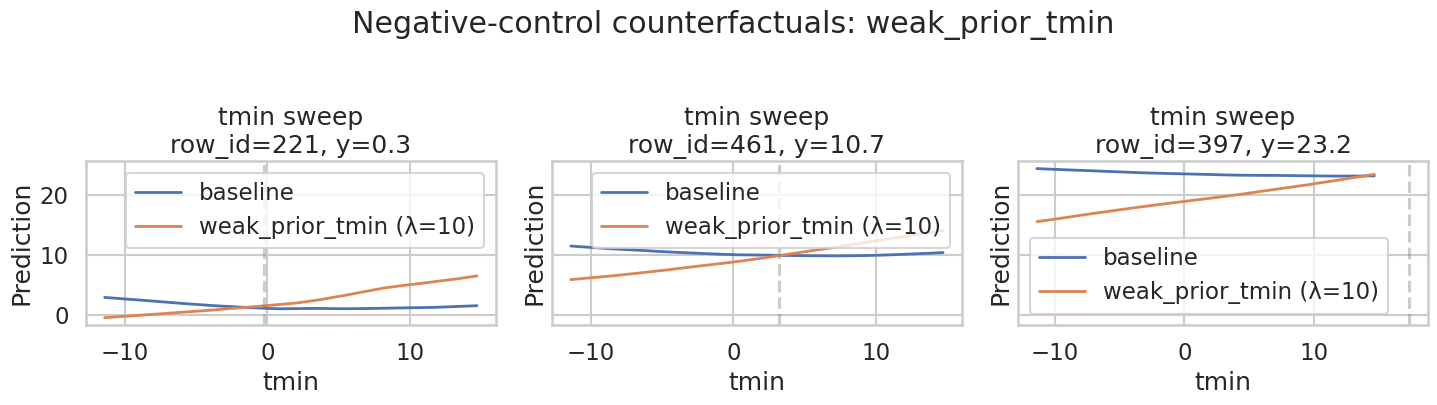

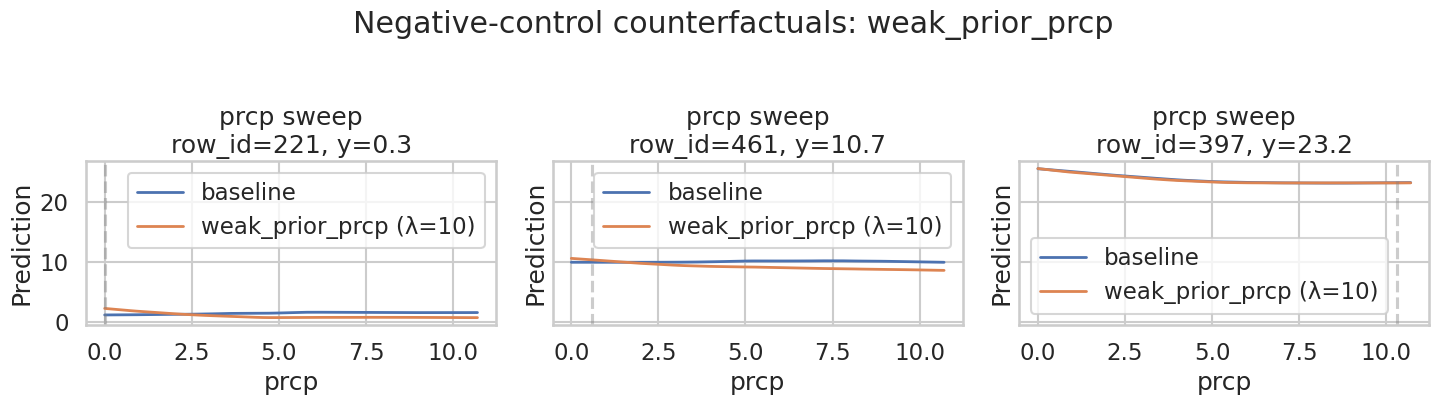

In [37]:
# Cell 37 - Qualitative comparison: baseline vs selected negative-control models
# This uses the same representative test rows as a simple visual sanity check.

qual_test_df = data.test_df.copy().reset_index(drop=True)
qual_test_df["row_id"] = np.arange(len(qual_test_df))
qual_test_df["y_true"] = data.y_test.astype(float)
qual_test_df["baseline_pred"] = predict_numpy(selected_model_store[0.0].to(device), data.X_test, device=device)

for j, name in enumerate(feature_cols):
    qual_test_df[f"{name}__scaled"] = data.X_test[:, j]

rep_rows = select_representative_rows(
    qual_test_df,
    col="y_true",
    quantiles=(0.1, 0.5, 0.9),
)

print("Representative test rows for negative-control plots:")
display(
    rep_rows[
        ["row_id", "datetime", "y_true", "baseline_pred", "tmin", "tavg", "tmax", "prcp"]
    ].round(3)
)

for spec in negative_control_specs:
    spec_name = spec["spec_name"]
    spec_features = list(spec["features"])

    key = (spec_name, float(selected_negative_lambda_for_plots))
    if key not in negative_model_store:
        continue

    neg_model = negative_model_store[key].to(device)
    baseline_model_for_plots = selected_model_store[0.0].to(device)

    for feature_name in spec_features:
        grid_orig = np.linspace(
            data.train_df[feature_name].quantile(0.05),
            data.train_df[feature_name].quantile(0.95),
            60,
        )

        fig, axes = plt.subplots(1, len(rep_rows), figsize=(5 * len(rep_rows), 4), sharey=True)
        if len(rep_rows) == 1:
            axes = [axes]

        for ax, (_, base_row) in zip(axes, rep_rows.iterrows()):
            cf_base = make_counterfactual_sweep_df(
                baseline_model_for_plots,
                base_row=base_row,
                feature_name=feature_name,
                grid_orig=grid_orig,
                feature_cols=feature_cols,
                scaler=data.scaler,
                device=device,
            )
            cf_neg = make_counterfactual_sweep_df(
                neg_model,
                base_row=base_row,
                feature_name=feature_name,
                grid_orig=grid_orig,
                feature_cols=feature_cols,
                scaler=data.scaler,
                device=device,
            )

            ax.plot(cf_base["feature_value_orig"], cf_base["prediction"], label="baseline", linewidth=2)
            ax.plot(
                cf_neg["feature_value_orig"],
                cf_neg["prediction"],
                label=f"{spec_name} (λ={selected_negative_lambda_for_plots:g})",
                linewidth=2,
            )
            ax.axvline(float(base_row[feature_name]), color="gray", linestyle="--", alpha=0.4)
            ax.set_title(
                f"{feature_name} sweep\nrow_id={int(base_row['row_id'])}, y={base_row['y_true']:.1f}"
            )
            ax.set_xlabel(feature_name)
            ax.set_ylabel("Prediction")
            ax.legend()

        plt.suptitle(f"Negative-control counterfactuals: {spec_name}", y=1.03)
        plt.tight_layout()
        plt.show()

In [38]:
# Cell 38 - Qualitative comparison: baseline vs selected negative-control models

negative_counterfactual_rows = []

for spec in negative_control_specs:
    spec_name = str(spec["spec_name"])
    spec_features = list(spec["features"])
    spec_sign_dict = {str(k): int(v) for k, v in spec["sign_dict"].items()}

    key = (spec_name, float(selected_negative_lambda_for_plots))
    if key not in negative_model_store:
        continue

    neg_model = negative_model_store[key].to(device)

    for feature_name in spec_features:
        grid_orig = np.linspace(
            data.train_df[feature_name].quantile(0.05),
            data.train_df[feature_name].quantile(0.95),
            21,
        )

        for _, base_row in rep_rows.iterrows():
            cf_neg = make_counterfactual_sweep_df(
                neg_model,
                base_row=base_row,
                feature_name=feature_name,
                grid_orig=grid_orig,
                feature_cols=feature_cols,
                scaler=data.scaler,
                device=device,
            )

            row = {
                "spec_name": spec_name,
                "row_id": int(base_row["row_id"]),
                "y_true": float(base_row["y_true"]),
                "feature": feature_name,
                "model": f"{spec_name}_lambda_{selected_negative_lambda_for_plots:g}",
            }

            # summary under the imposed bad/weak prior
            imposed_summary = summarize_counterfactual_curve(
                cf_neg,
                sign=int(spec_sign_dict[feature_name]),
            )
            row.update(
                {
                    "grid_low": imposed_summary["grid_low"],
                    "grid_mid": imposed_summary["grid_mid"],
                    "grid_high": imposed_summary["grid_high"],
                    "pred_low": imposed_summary["pred_low"],
                    "pred_mid": imposed_summary["pred_mid"],
                    "pred_high": imposed_summary["pred_high"],
                    "delta_high_minus_low": imposed_summary["delta_high_minus_low"],
                    "imposed_monotone_on_grid": imposed_summary["monotone_on_grid"],
                    "imposed_wrong_steps": imposed_summary["n_wrong_steps"],
                }
            )

            # summary under the original main sign, if available for this feature
            if feature_name in sign_dict:
                main_summary = summarize_counterfactual_curve(
                    cf_neg,
                    sign=int(sign_dict[feature_name]),
                )
                row["main_sign_monotone_on_grid"] = main_summary["monotone_on_grid"]
                row["main_sign_wrong_steps"] = main_summary["n_wrong_steps"]
            else:
                row["main_sign_monotone_on_grid"] = np.nan
                row["main_sign_wrong_steps"] = np.nan

            negative_counterfactual_rows.append(row)

negative_counterfactual_summary_df = (
    pd.DataFrame(negative_counterfactual_rows)
    .sort_values(["spec_name", "feature", "row_id"])
    .reset_index(drop=True)
    .round(4)
)

display(negative_counterfactual_summary_df)

,spec_name,row_id,y_true,feature,model,grid_low,grid_mid,grid_high,pred_low,pred_mid,pred_high,delta_high_minus_low,imposed_monotone_on_grid,imposed_wrong_steps,main_sign_monotone_on_grid,main_sign_wrong_steps
0,weak_prior_prcp,221,0.3,prcp,weak_prior_prcp_lambda_10,0.000,5.3500,10.7,2.2345,0.7106,0.6933,-1.5412,False,6,NaN,NaN
1,weak_prior_prcp,397,23.2,prcp,weak_prior_prcp_lambda_10,0.000,5.3500,10.7,25.6525,23.3377,23.2599,-2.3926,False,4,NaN,NaN
2,weak_prior_prcp,461,10.7,prcp,weak_prior_prcp_lambda_10,0.000,5.3500,10.7,10.6147,9.1460,8.6071,-2.0075,True,0,NaN,NaN
3,weak_prior_tmin,221,0.3,tmin,weak_prior_tmin_lambda_10,-11.400,1.6500,14.7,-0.4107,1.9412,6.5374,6.9481,True,0,NaN,NaN
4,weak_prior_tmin,397,23.2,tmin,weak_prior_tmin_lambda_10,-11.400,1.6500,14.7,15.5765,19.3826,23.4433,7.8668,True,0,NaN,NaN
5,weak_prior_tmin,461,10.7,tmin,weak_prior_tmin_lambda_10,-11.400,1.6500,14.7,5.9299,9.3753,14.1193,8.1893,True,0,NaN,NaN
6,wrong_sign_tavg,221,0.3,tavg,wrong_sign_tavg_lambda_10,-7.800,5.8000,19.4,3.5490,-0.2455,-2.0422,-5.5912,True,0,False,20.0
7,wrong_sign_tavg,397,23.2,tavg,wrong_sign_tavg_lambda_10,-7.800,5.8000,19.4,29.8795,24.0533,18.1965,-11.6831,True,0,False,20.0
8,wrong_sign_tavg,461,10.7,tavg,wrong_sign_tavg_lambda_10,-7.800,5.8000,19.4,14.5899,9.9521,7.2991,-7.2908,True,0,False,20.0
9,wrong_sign_tmax,221,0.3,tmax,wrong_sign_tmax_lambda_10,-4.525,10.6375,25.8,5.2759,-0.6490,-2.2592,-7.5351,True,0,False,20.0


## Suggested interpretation of the sanity checks

If the code works as intended, then under a deliberately poor monotonic prior we expect one or more of the following:

- the model becomes more compatible with the **bad imposed rule**,
- the model becomes worse under the **correct original monotonic interpretation**,
- predictive RMSE worsens or at least fails to improve,
- local counterfactual sweeps flatten or bend in the wrong direction.

This does not mean every bad prior must destroy performance completely.  
The key point is that the model should **respond** to the imposed bad prior.

## Negative-control summary plots

The following plots mirror the main monotonicity summary plots, but for the deliberately poor monotonic priors.

For each negative-control specification, we show:

1. **Test RMSE**  
   predictive performance on the real task,

2. **Violation rate under the imposed bad prior**  
   this shows whether the model is responding to the bad constraint,

3. **Violation rate under the original correct monotonic interpretation**  
   this shows whether the bad prior harms the desired monotonic behavior,

4. **Best validation objective**  
   the objective used during training for that negative-control model.

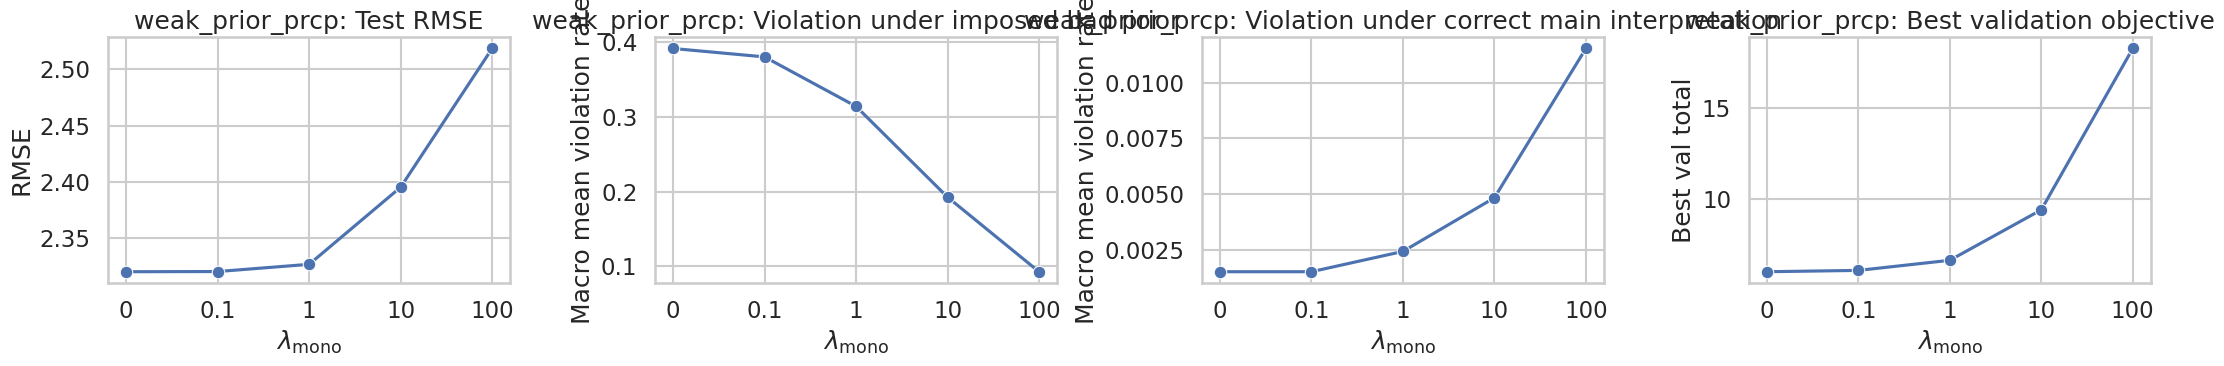

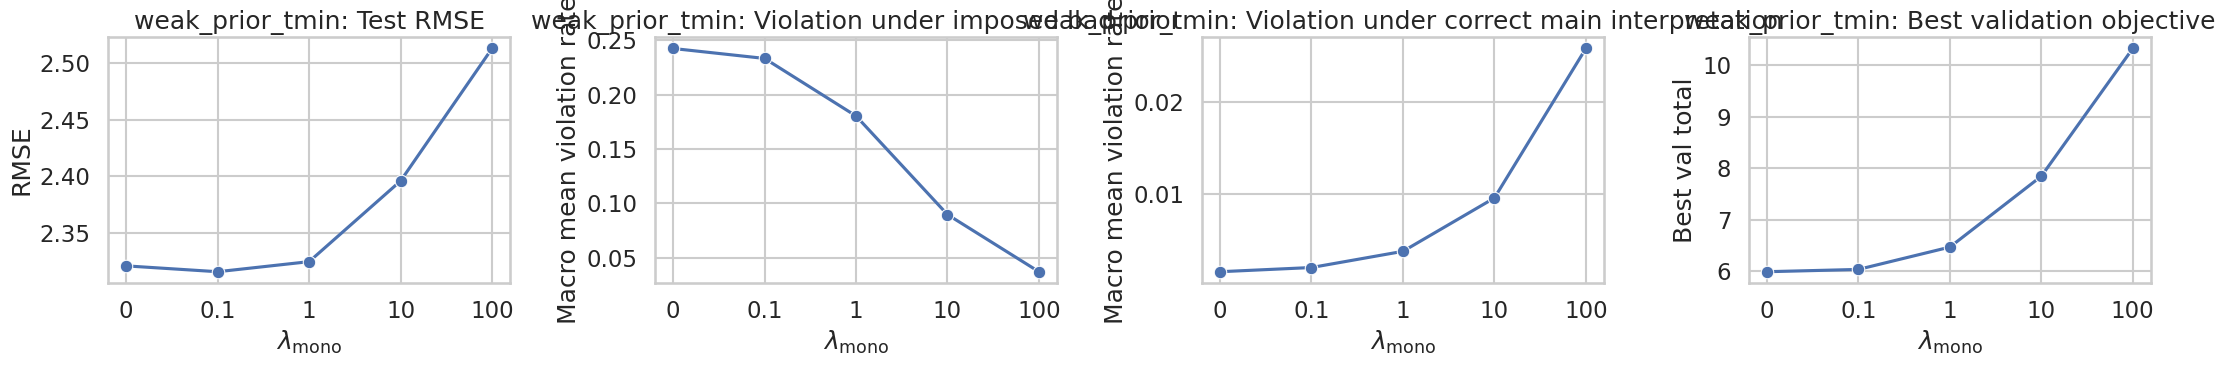

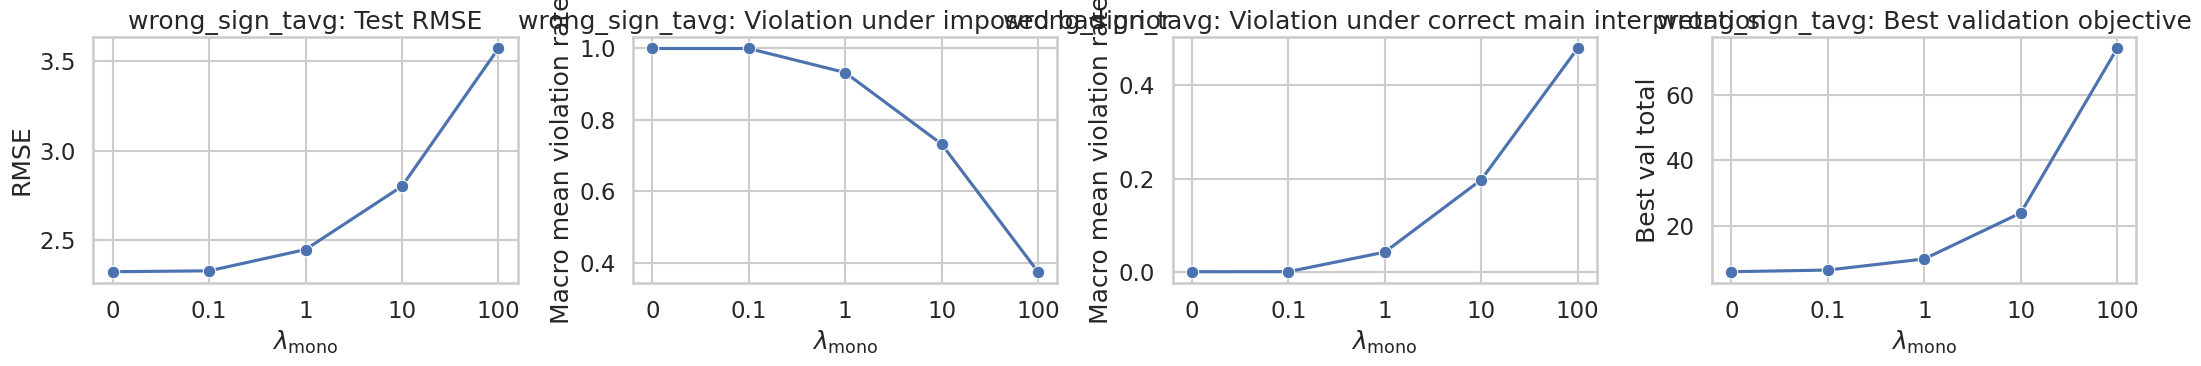

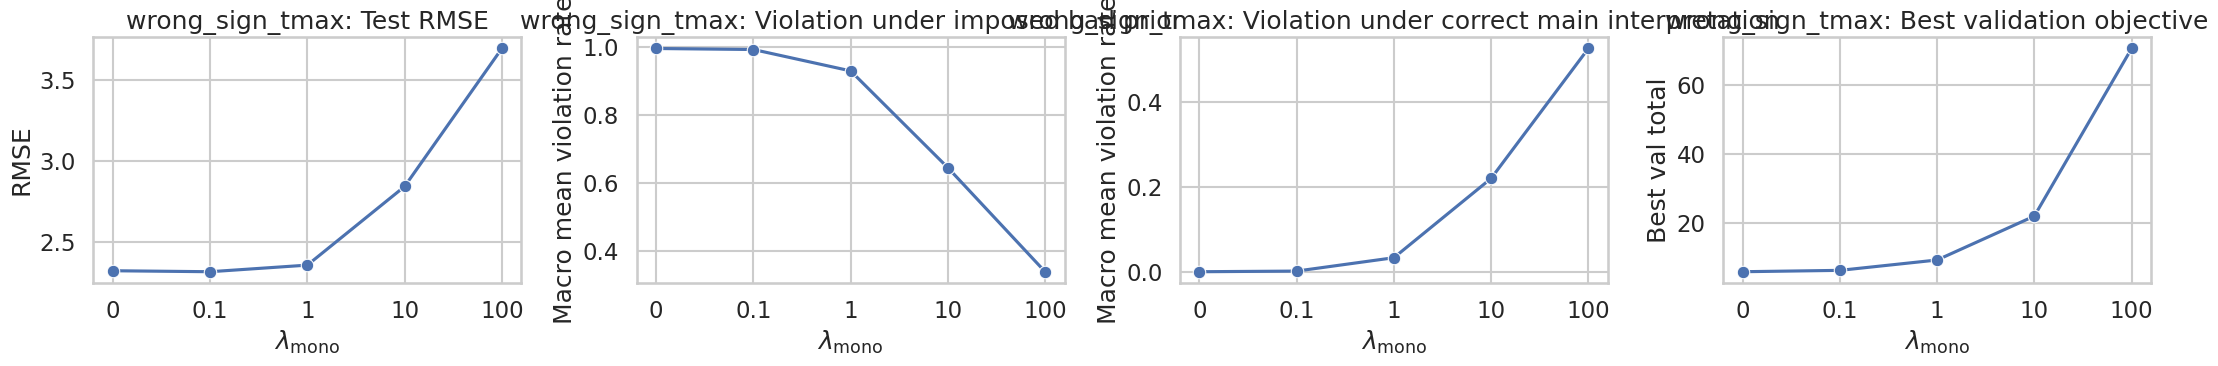

In [39]:
# Cell 39 - Negative-control summary plots: one figure per specification

negative_plot_df = negative_agg_df.copy()
negative_plot_df["lambda_label"] = negative_plot_df["lambda_mono"].map(lambda x: f"{x:g}")

for spec_name in negative_plot_df["spec_name"].astype(str).unique():
    sub = (
        negative_plot_df.loc[negative_plot_df["spec_name"] == spec_name]
        .copy()
        .sort_values("lambda_mono")
    )

    fig, axes = plt.subplots(1, 4, figsize=(22, 4))

    sns.lineplot(data=sub, x="lambda_label", y="test_rmse_mean", marker="o", ax=axes[0])
    axes[0].set_title(f"{spec_name}: Test RMSE")
    axes[0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[0].set_ylabel("RMSE")

    sns.lineplot(data=sub, x="lambda_label", y="exp_test_pair_violation_macro_mean", marker="o", ax=axes[1])
    axes[1].set_title(f"{spec_name}: Violation under imposed bad prior")
    axes[1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[1].set_ylabel("Macro mean violation rate")

    sns.lineplot(data=sub, x="lambda_label", y="main_test_pair_violation_macro_mean", marker="o", ax=axes[2])
    axes[2].set_title(f"{spec_name}: Violation under correct main interpretation")
    axes[2].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[2].set_ylabel("Macro mean violation rate")

    sns.lineplot(data=sub, x="lambda_label", y="best_val_total_mean", marker="o", ax=axes[3])
    axes[3].set_title(f"{spec_name}: Best validation objective")
    axes[3].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[3].set_ylabel("Best val total")

    plt.tight_layout()
    plt.show()

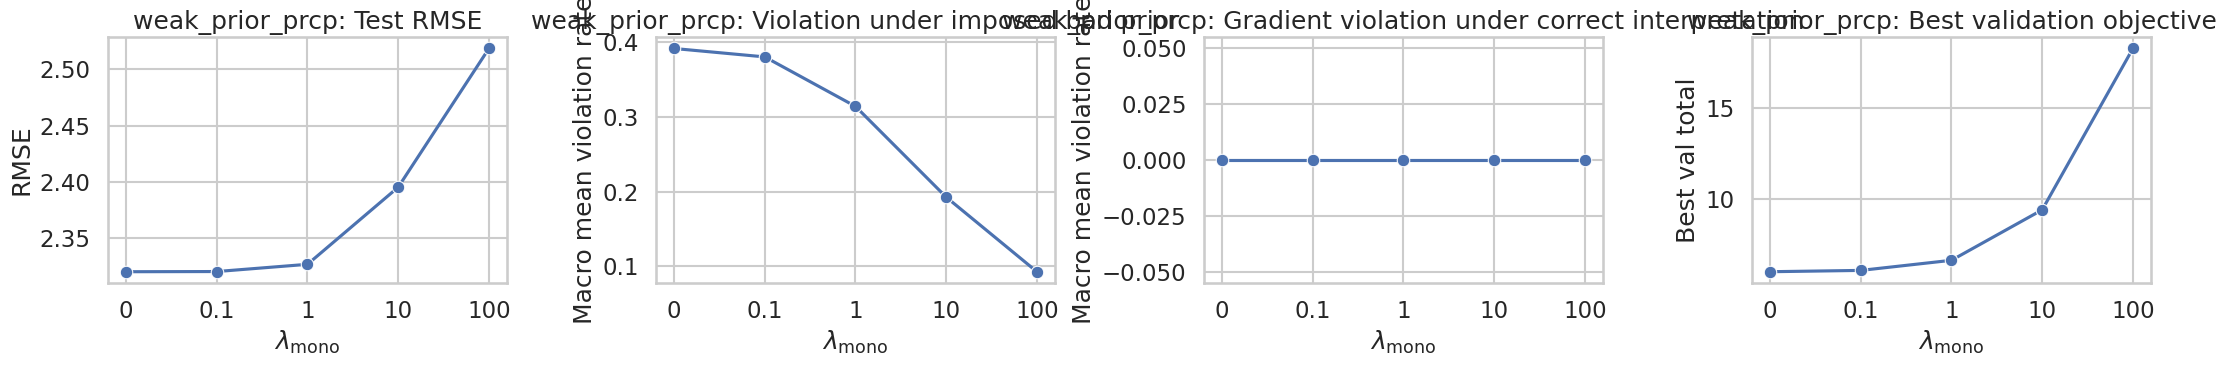

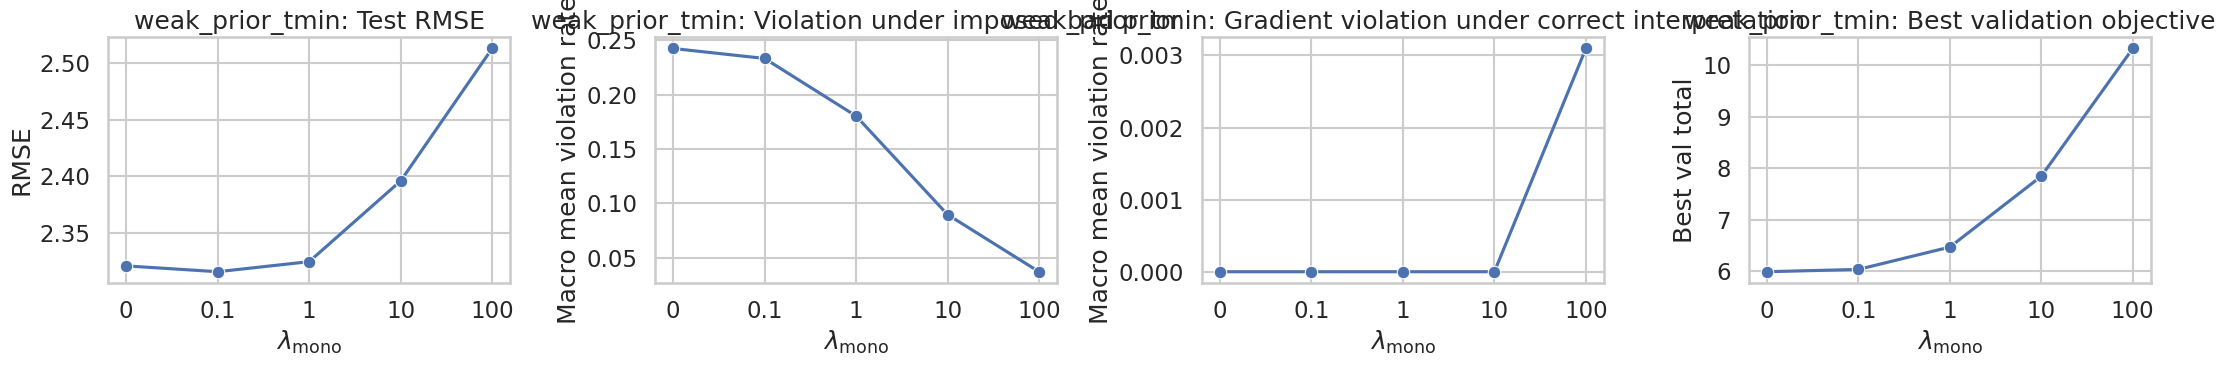

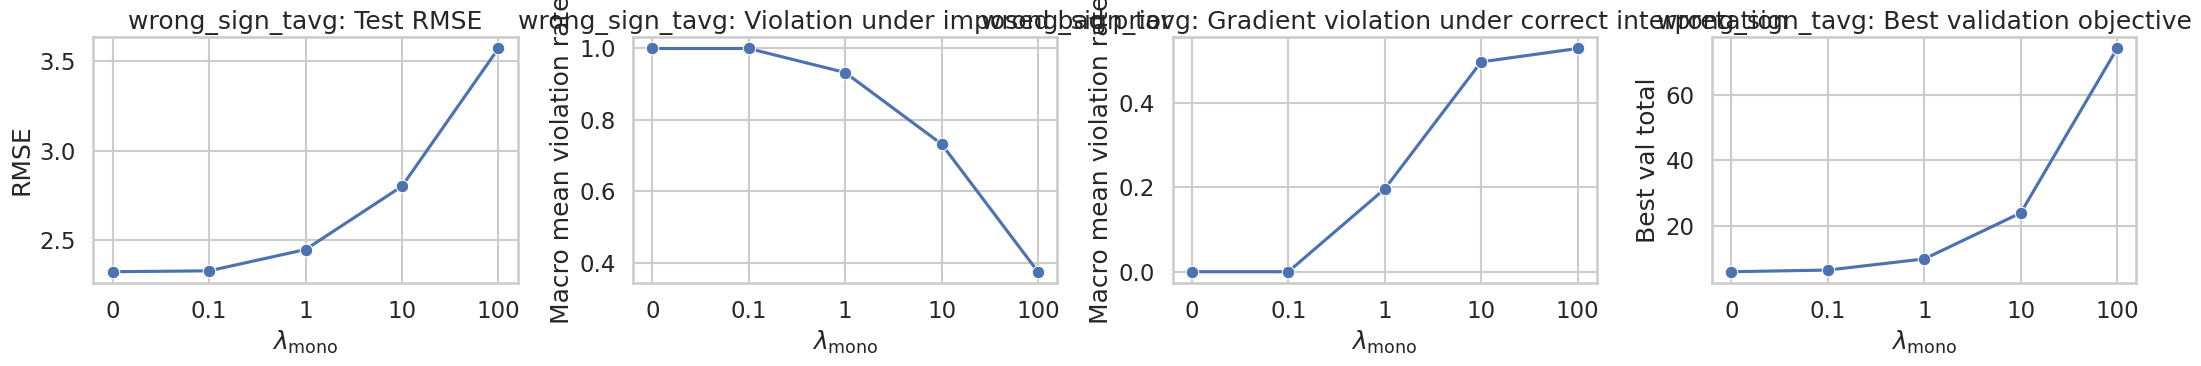

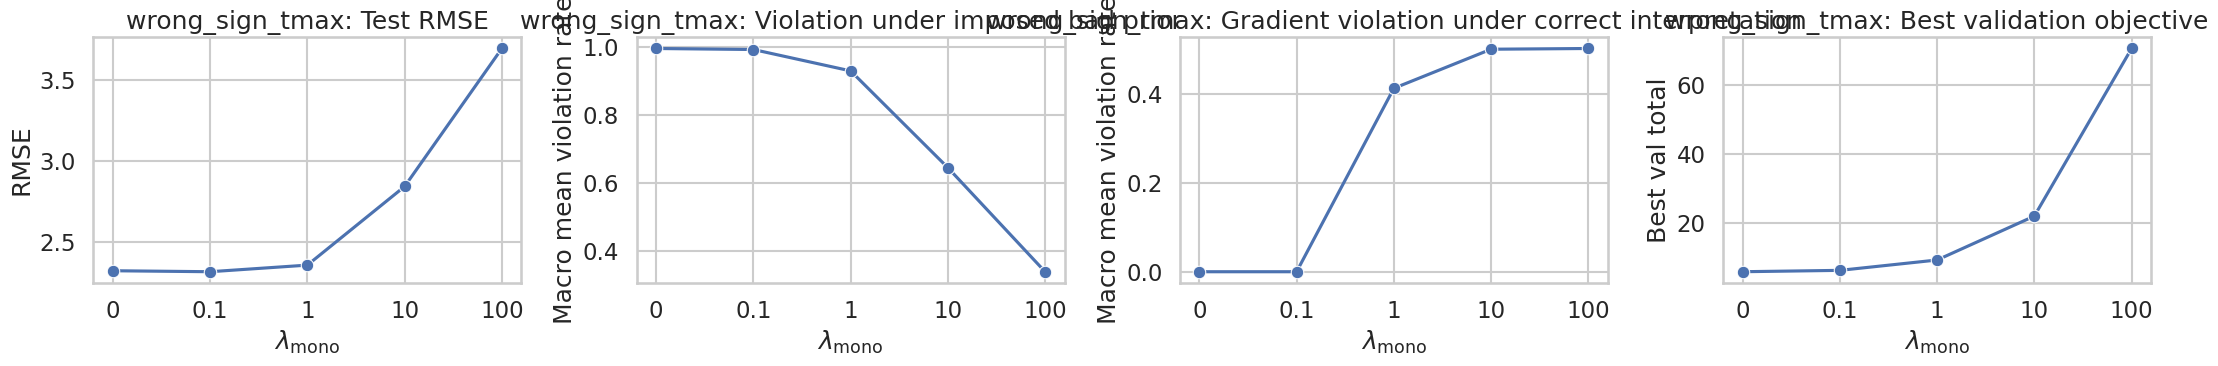

In [40]:
# Cell 40 - Negative-control summary plots with gradient-based third panel

negative_plot_df = negative_agg_df.copy()
negative_plot_df["lambda_label"] = negative_plot_df["lambda_mono"].map(lambda x: f"{x:g}")

for spec_name in negative_plot_df["spec_name"].astype(str).unique():
    sub = (
        negative_plot_df.loc[negative_plot_df["spec_name"] == spec_name]
        .copy()
        .sort_values("lambda_mono")
    )

    fig, axes = plt.subplots(1, 4, figsize=(22, 4))

    sns.lineplot(data=sub, x="lambda_label", y="test_rmse_mean", marker="o", ax=axes[0])
    axes[0].set_title(f"{spec_name}: Test RMSE")
    axes[0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[0].set_ylabel("RMSE")

    sns.lineplot(data=sub, x="lambda_label", y="exp_test_pair_violation_macro_mean", marker="o", ax=axes[1])
    axes[1].set_title(f"{spec_name}: Violation under imposed bad prior")
    axes[1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[1].set_ylabel("Macro mean violation rate")

    sns.lineplot(data=sub, x="lambda_label", y="main_test_grad_violation_macro_mean", marker="o", ax=axes[2])
    axes[2].set_title(f"{spec_name}: Gradient violation under correct interpretation")
    axes[2].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[2].set_ylabel("Macro mean violation rate")

    sns.lineplot(data=sub, x="lambda_label", y="best_val_total_mean", marker="o", ax=axes[3])
    axes[3].set_title(f"{spec_name}: Best validation objective")
    axes[3].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
    axes[3].set_ylabel("Best val total")

    plt.tight_layout()
    plt.show()

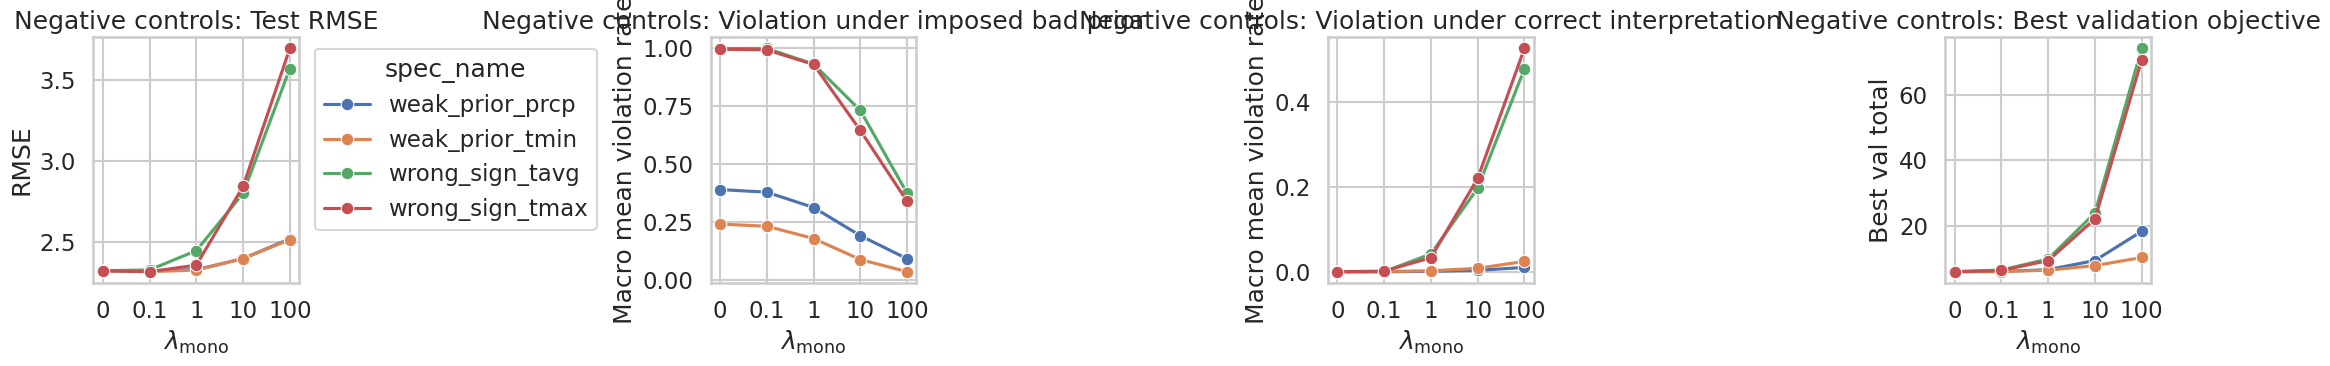

In [41]:
# Cell 41 - Combined negative-control summary plots with hue = spec_name

negative_plot_df = negative_agg_df.copy()
negative_plot_df["lambda_label"] = negative_plot_df["lambda_mono"].map(lambda x: f"{x:g}")

fig, axes = plt.subplots(1, 4, figsize=(22, 4))

sns.lineplot(
    data=negative_plot_df,
    x="lambda_label",
    y="test_rmse_mean",
    hue="spec_name",
    marker="o",
    ax=axes[0],
)
axes[0].set_title("Negative controls: Test RMSE")
axes[0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[0].set_ylabel("RMSE")

sns.lineplot(
    data=negative_plot_df,
    x="lambda_label",
    y="exp_test_pair_violation_macro_mean",
    hue="spec_name",
    marker="o",
    ax=axes[1],
)
axes[1].set_title("Negative controls: Violation under imposed bad prior")
axes[1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[1].set_ylabel("Macro mean violation rate")

sns.lineplot(
    data=negative_plot_df,
    x="lambda_label",
    y="main_test_pair_violation_macro_mean",
    hue="spec_name",
    marker="o",
    ax=axes[2],
)
axes[2].set_title("Negative controls: Violation under correct interpretation")
axes[2].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[2].set_ylabel("Macro mean violation rate")

sns.lineplot(
    data=negative_plot_df,
    x="lambda_label",
    y="best_val_total_mean",
    hue="spec_name",
    marker="o",
    ax=axes[3],
)
axes[3].set_title("Negative controls: Best validation objective")
axes[3].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[3].set_ylabel("Best val total")

# Keep only one legend
for ax in axes[1:]:
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()

axes[0].legend(title="spec_name", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()